In [12]:

# ================================================================
# EXPERIMENT 05 — ADAPTIVE TEACHER THRESHOLD ABLATION
# Configuration A: Original Adaptive Teacher (0.80)
# Configuration B: Fixed confidence threshold (0.70)
#
# This cell:
# 1. Verifies datasets and initialization checkpoint
# 2. Creates controlled experiment configurations
# 3. Fixes Detectron2's dataset path
# 4. Runs Configuration B with live training output
# 5. Verifies the resulting checkpoint
#
# Configuration C (fog-aware method) is NOT implemented here.
# ================================================================

import os
import sys
import yaml
import json
import time
import shlex
import hashlib
import subprocess
from pathlib import Path
from datetime import datetime

# ------------------------------------------------
# 1. EXPERIMENT SETTINGS
# ------------------------------------------------

ROOT = Path("/workspace")

REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

BASE = ROOT / "experiments/cityscapes_to_foggy"

EXP05 = BASE / "experiment_05_fog_aware_teacher"

CONFIG_DIR = EXP05 / "configs"

BASELINE_CONFIG = (
    BASE /
    "adaptive_teacher/pilot_5000_warmstart_v2/"
    "adaptive_teacher_5000.yaml"
)

BASELINE_CHECKPOINT = (
    BASE /
    "adaptive_teacher/pilot_5000_warmstart_v2/"
    "model_final.pth"
)

TRAIN_SCRIPT = REPO / "train_net.py"

DATA_ROOT = ROOT / "datasets"

MAX_ITER = 5000

START_TRAINING = True

# Set True only if you explicitly want to run
# a fresh 0.80 baseline with the same protocol.
RUN_BASELINE_080 = False

# ------------------------------------------------
# 2. VALIDATE FILES AND DATASETS
# ------------------------------------------------

print("=" * 75)
print("EXPERIMENT 05 — ENVIRONMENT VALIDATION")
print("=" * 75)

required_files = {
    "Adaptive Teacher repository": REPO,
    "Training script": TRAIN_SCRIPT,
    "Experiment 02 configuration": BASELINE_CONFIG,
    "Experiment 02 checkpoint": BASELINE_CHECKPOINT,
    "Cityscapes train images":
        DATA_ROOT / "cityscapes/leftImg8bit/train",
    "Cityscapes train annotations":
        DATA_ROOT / "cityscapes/gtFine/train",
    "Cityscapes validation images":
        DATA_ROOT / "cityscapes/leftImg8bit/val",
    "Foggy Cityscapes train images":
        DATA_ROOT / "cityscapes_foggy/leftImg8bit/train",
}

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    print(f"  {path}")

    if not exists:
        raise FileNotFoundError(
            f"Required path missing: {path}"
        )

CONFIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 3. LOAD ORIGINAL CONFIGURATION
# ------------------------------------------------

with BASELINE_CONFIG.open() as f:
    original_cfg = yaml.safe_load(f)

assert isinstance(original_cfg, dict)

assert (
    original_cfg["SEMISUPNET"]["BBOX_THRESHOLD"] == 0.80
), "Experiment 02 baseline threshold is not 0.80."

assert (
    original_cfg["SOLVER"]["MAX_ITER"] == MAX_ITER
), "Unexpected Experiment 02 training budget."

init_checkpoint = Path(
    original_cfg["MODEL"]["WEIGHTS"]
)

assert init_checkpoint.is_file(), (
    f"Initialization checkpoint missing: {init_checkpoint}"
)

print("\nINITIALIZATION CHECKPOINT")
print(init_checkpoint)

print("\nORIGINAL EXPERIMENT SETTINGS")
print("Threshold:",
      original_cfg["SEMISUPNET"]["BBOX_THRESHOLD"])
print("Iterations:",
      original_cfg["SOLVER"]["MAX_ITER"])
print("Burn-in:",
      original_cfg["SEMISUPNET"]["BURN_UP_STEP"])
print("Seed:", original_cfg["SEED"])

# ------------------------------------------------
# 4. CREATE CONTROLLED CONFIGURATIONS
# ------------------------------------------------

import copy

def prepare_config(name, threshold):

    cfg = copy.deepcopy(original_cfg)

    cfg["SEMISUPNET"]["BBOX_THRESHOLD"] = threshold

    cfg["OUTPUT_DIR"] = str(EXP05 / name)

    cfg_path = CONFIG_DIR / f"{name}.yaml"

    with cfg_path.open("w") as f:
        yaml.safe_dump(
            cfg,
            f,
            sort_keys=False
        )

    return cfg_path, cfg


config_a_path, config_a = prepare_config(
    "baseline_080", 0.80
)

config_b_path, config_b = prepare_config(
    "fixed_070", 0.70
)

def flatten_dict(obj, prefix=""):
    result = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            new_key = f"{prefix}.{key}" if prefix else key
            result.update(flatten_dict(value, new_key))
    else:
        result[prefix] = obj

    return result


flat_a = flatten_dict(config_a)
flat_b = flatten_dict(config_b)

differences = {
    key: (flat_a.get(key), flat_b.get(key))
    for key in set(flat_a) | set(flat_b)
    if flat_a.get(key) != flat_b.get(key)
}

allowed_differences = {
    "SEMISUPNET.BBOX_THRESHOLD",
    "OUTPUT_DIR",
}

assert set(differences) == allowed_differences, (
    f"Unexpected configuration differences: {differences}"
)

print("\nCONFIGURATION COMPARISON")

for key, values in sorted(differences.items()):
    print(f"{key}: {values[0]} -> {values[1]}")

print("\nPASS: Configuration-controlled ablation.")

# ------------------------------------------------
# 5. VERIFY TRAINING DATASET RESOLUTION
# ------------------------------------------------

# Detectron2's built-in Cityscapes registration
# may use a relative 'datasets/cityscapes' path.
# Running from /workspace makes that path valid.

relative_cityscapes = (
    ROOT / "datasets/cityscapes/leftImg8bit/train"
)

assert relative_cityscapes.is_dir()

print("\nDATASET ROOT:", DATA_ROOT)
print("Working directory for training:", ROOT)

# ------------------------------------------------
# 6. VERIFY GPU
# ------------------------------------------------

import torch

print("\nGPU VALIDATION")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------
# 7. TRAINING LAUNCHER WITH LIVE LOGS
# ------------------------------------------------

def train_experiment(name, cfg_path):

    output_dir = EXP05 / name

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Never overwrite an existing completed run.
    for checkpoint_name in [
        "model_final.pth",
        "last_checkpoint",
    ]:
        checkpoint_path = output_dir / checkpoint_name

        if checkpoint_path.exists():
            raise RuntimeError(
                f"Existing checkpoint found: {checkpoint_path}. "
                "Inspect the run before restarting."
            )

    command = [
        sys.executable,
        str(TRAIN_SCRIPT),
        "--num-gpus", "1",
        "--config-file", str(cfg_path),
    ]

    env = os.environ.copy()

    env["DETECTRON2_DATASETS"] = str(DATA_ROOT)

    env["PYTHONUNBUFFERED"] = "1"

    # Make recovered repository importable.
    compat_dir = (
        BASE /
        "source_only/pilot_1000_v1/python_compat"
    )

    python_paths = [
        str(REPO),
    ]

    if compat_dir.is_dir():
        python_paths.append(str(compat_dir))

    if env.get("PYTHONPATH"):
        python_paths.append(env["PYTHONPATH"])

    env["PYTHONPATH"] = os.pathsep.join(
        python_paths
    )

    log_path = output_dir / "training.log"

    print("\n" + "=" * 75)
    print("STARTING EXPERIMENT:", name)
    print("=" * 75)

    print("Command:", shlex.join(command))
    print("Working directory:", ROOT)
    print("Dataset root:", env["DETECTRON2_DATASETS"])
    print("Log:", log_path)

    print("\nTraining output:\n", flush=True)

    start_time = time.time()

    # Use Popen to stream logs while training runs.
    with log_path.open("w", buffering=1) as log:

        process = subprocess.Popen(
            command,
            cwd=str(ROOT),
            env=env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                log.write(line)

                # Display important progress lines.
                keywords = [
                    "iter:",
                    "eta:",
                    "total_loss:",
                    "Traceback",
                    "Error",
                    "Exception",
                    "Saving checkpoint",
                    "Evaluation results",
                ]

                if any(word in line for word in keywords):
                    print(line.rstrip(), flush=True)

            return_code = process.wait()

        except KeyboardInterrupt:
            print(
                "\nNotebook interrupted. "
                "Stopping training process."
            )
            process.terminate()
            try:
                process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            raise

    elapsed_minutes = (
        time.time() - start_time
    ) / 60

    print("\nElapsed minutes:", round(elapsed_minutes, 2))

    if return_code != 0:

        print("\nTRAINING FAILED")
        print("Exit code:", return_code)

        print("\nLAST 70 LOG LINES")
        print("-" * 75)

        lines = log_path.read_text(
            errors="replace"
        ).splitlines()

        print("\n".join(lines[-70:]))

        raise RuntimeError(
            f"Experiment {name} failed. "
            f"Inspect {log_path}"
        )

    print("\nTraining subprocess completed.")

    final_checkpoint = (
        output_dir / "model_final.pth"
    )

    if not final_checkpoint.exists():
        raise RuntimeError(
            "Training exited successfully, but "
            "model_final.pth was not found. "
            "Inspect the output directory."
        )

    print("Final checkpoint:", final_checkpoint)

    return final_checkpoint


# ------------------------------------------------
# 8. RECORD EXPERIMENT METADATA
# ------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


manifest = {
    "experiment": "05",
    "description": "Adaptive Teacher threshold ablation",
    "source_dataset": "Cityscapes",
    "target_dataset": "Foggy Cityscapes",
    "baseline_threshold": 0.80,
    "ablation_threshold": 0.70,
    "max_iterations": MAX_ITER,
    "burn_in": original_cfg["SEMISUPNET"]["BURN_UP_STEP"],
    "seed": original_cfg["SEED"],
    "initialization_checkpoint": str(init_checkpoint),
    "initialization_sha256": sha256_file(init_checkpoint),
    "existing_baseline_checkpoint": str(BASELINE_CHECKPOINT),
    "baseline_config": str(BASELINE_CONFIG),
    "baseline_080_config": str(config_a_path),
    "fixed_070_config": str(config_b_path),
    "fog_aware_method_implemented": False,
    "created_at": datetime.now().isoformat(),
}

manifest_path = EXP05 / "experiment_manifest.json"

with manifest_path.open("w") as f:
    json.dump(
        manifest,
        f,
        indent=2
    )

print("\nExperiment manifest:", manifest_path)

# ------------------------------------------------
# 9. START CONFIGURATION B
# ------------------------------------------------

if START_TRAINING:

    if RUN_BASELINE_080:
        print("\nRunning a fresh 0.80 baseline.")
        train_experiment(
            "baseline_080",
            config_a_path
        )
    else:
        print(
            "\nReusing existing Experiment 02 "
            "baseline checkpoint for Configuration A."
        )

    print("\nStarting fixed-threshold 0.70 training.")

    final_checkpoint_b = train_experiment(
        "fixed_070",
        config_b_path
    )

    print("\n" + "=" * 75)
    print("EXPERIMENT 05 — CONFIGURATION B COMPLETE")
    print("=" * 75)
    print("Checkpoint:", final_checkpoint_b)

else:
    print("\nDry run complete. Training not started.")

# ------------------------------------------------
# 10. SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("EXPERIMENT 05 SUMMARY")
print("=" * 75)

print("Configuration A:")
print("  Threshold: 0.80")
print("  Existing checkpoint:", BASELINE_CHECKPOINT)

print("\nConfiguration B:")
print("  Threshold: 0.70")
print("  Output:", EXP05 / "fixed_070")

print("\nConfiguration C:")
print("  Proposed fog-aware pseudo-label filtering")
print("  Status: NOT IMPLEMENTED")

print("\nNext stage:")
print("  Evaluate Configuration B on light, medium,")
print("  and strong fog using Experiment 03 protocol.")


EXPERIMENT 05 — ENVIRONMENT VALIDATION
Adaptive Teacher repository: FOUND
  /workspace/adaptive_teacher_recovered/adaptive_teacher
Training script: FOUND
  /workspace/adaptive_teacher_recovered/adaptive_teacher/train_net.py
Experiment 02 configuration: FOUND
  /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/adaptive_teacher_5000.yaml
Experiment 02 checkpoint: FOUND
  /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/model_final.pth
Cityscapes train images: FOUND
  /workspace/datasets/cityscapes/leftImg8bit/train
Cityscapes train annotations: FOUND
  /workspace/datasets/cityscapes/gtFine/train
Cityscapes validation images: FOUND
  /workspace/datasets/cityscapes/leftImg8bit/val
Foggy Cityscapes train images: FOUND
  /workspace/datasets/cityscapes_foggy/leftImg8bit/train

INITIALIZATION CHECKPOINT
/workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_v1/source_only_teacher_student_init.pth

ORIGINAL EXP

EXPERIMENT 05B — EVALUATION
GPU: NVIDIA RTX PRO 4000 Blackwell
Output: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070

VALIDATING INFERENCE CONFIGURATIONS
  MODEL.META_ARCHITECTURE: DAobjTwoStagePseudoLabGeneralizedRCNN
  MODEL.BACKBONE.NAME: build_vgg_backbone
  MODEL.PROPOSAL_GENERATOR.NAME: PseudoLabRPN
  MODEL.ROI_HEADS.NAME: StandardROIHeadsPseudoLab
  MODEL.ROI_HEADS.SCORE_THRESH_TEST: 0.05
  MODEL.ROI_HEADS.NUM_CLASSES: 8
  INPUT.FORMAT: BGR
  INPUT.MIN_SIZE_TEST: 800
  INPUT.MAX_SIZE_TEST: 1333
  TEST.DETECTIONS_PER_IMAGE: 100
Inference configuration validation passed.

All custom model components registered.
Registered light: 500 images
Registered medium: 500 images
Registered strong: 500 images

Loading threshold 0.70 teacher...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0
0.70 teacher model loaded successfully.

EVALUATING THRESHOLD 0.70 — LIGHT FOG


/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Loading and preparing results...
DONE (t=0.34s)
creating index...
index created!
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.150
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.327
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.121
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.164
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.324
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.118
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.227
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.244
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.030
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.228
 Average Recall     (AR) @[ IoU=0.50:0.

model,fixed_070,fixed_080,delta_pp
fog_density,,,
light,14.994,15.253,-0.259
medium,14.603,14.053,0.550
strong,13.385,13.533,-0.149



AP50 COMPARISON


model,fixed_070,fixed_080,delta_pp
fog_density,,,
light,32.714,33.081,-0.367
medium,31.066,31.380,-0.314
strong,28.020,28.578,-0.558


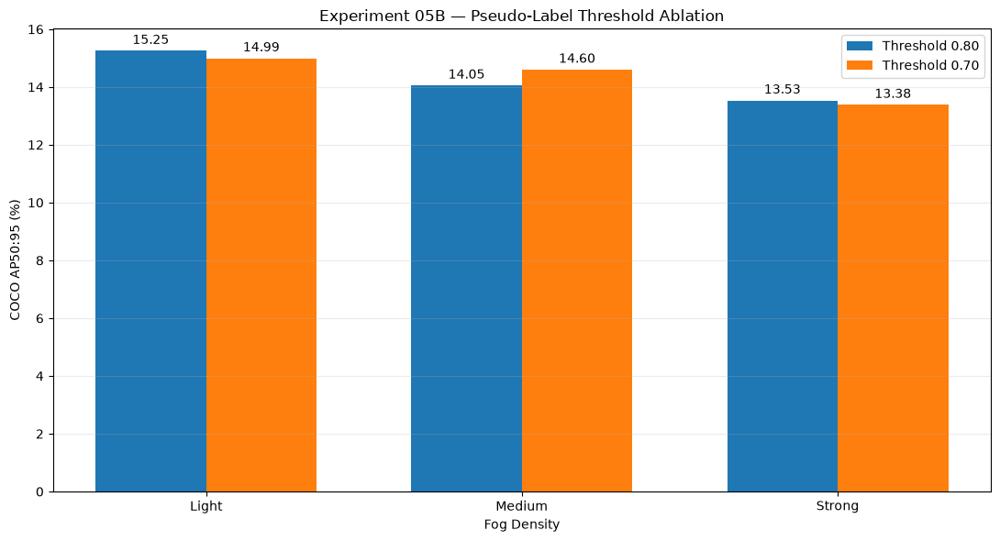

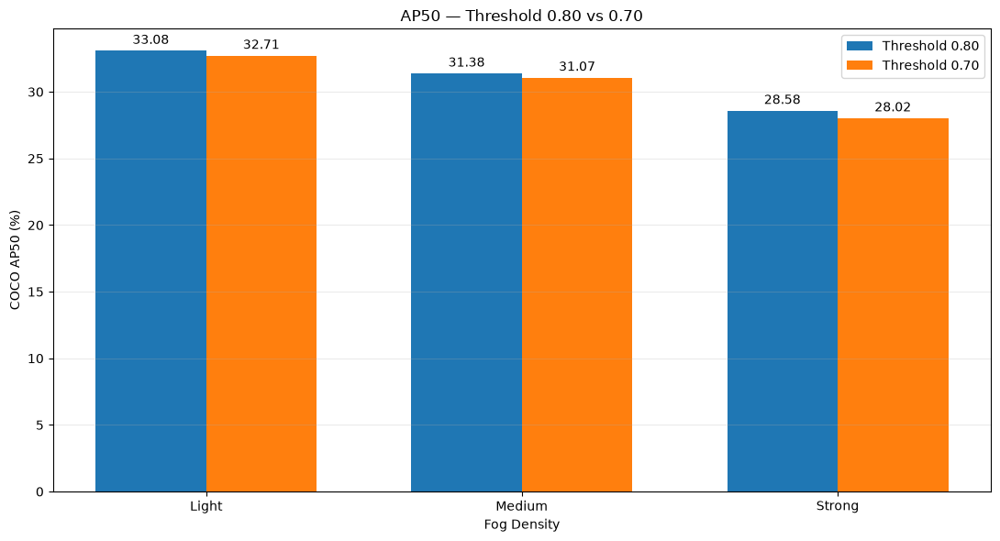

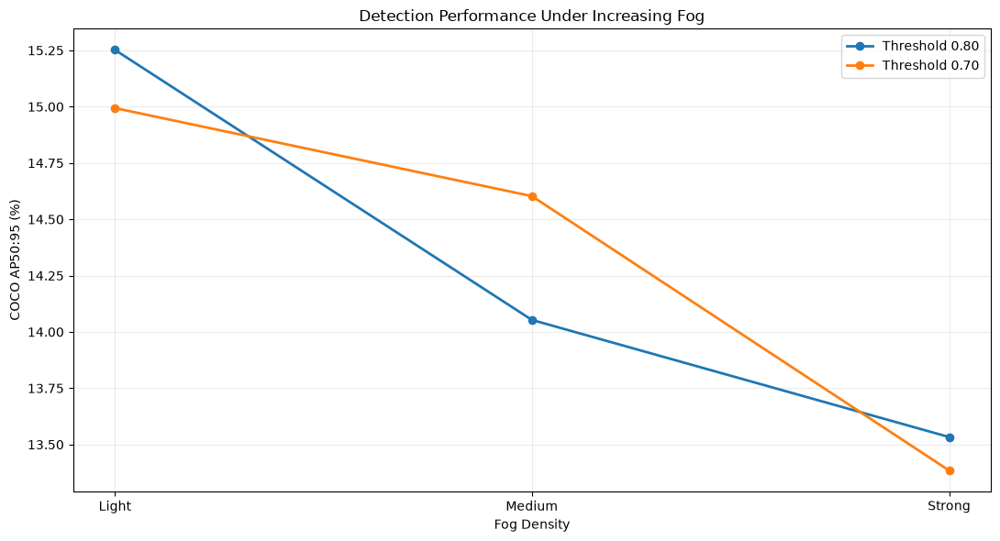

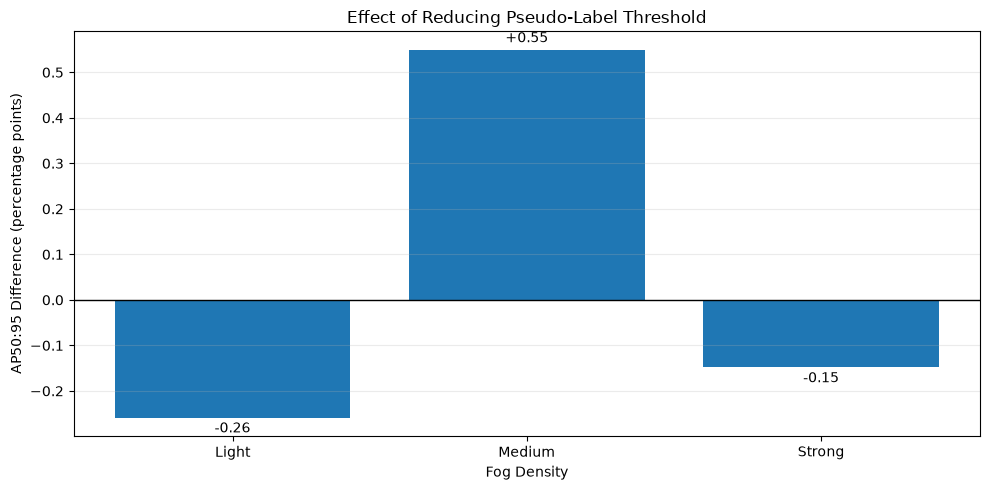

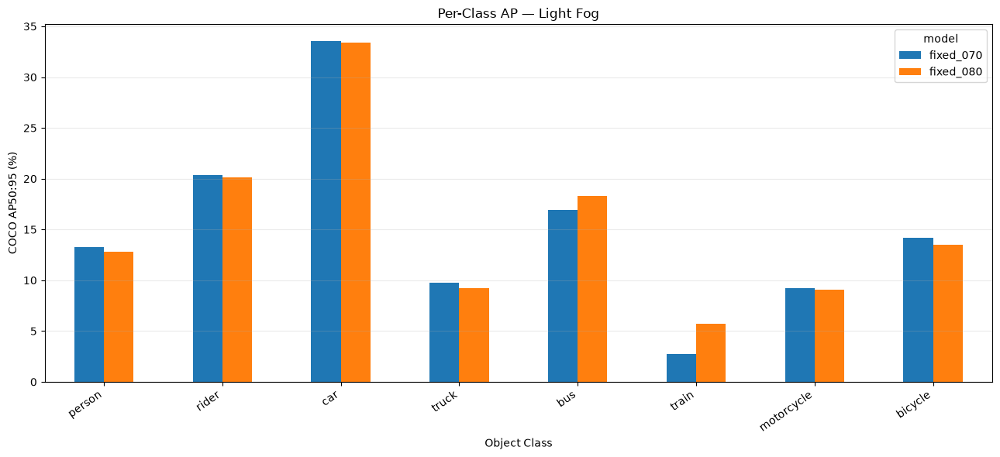

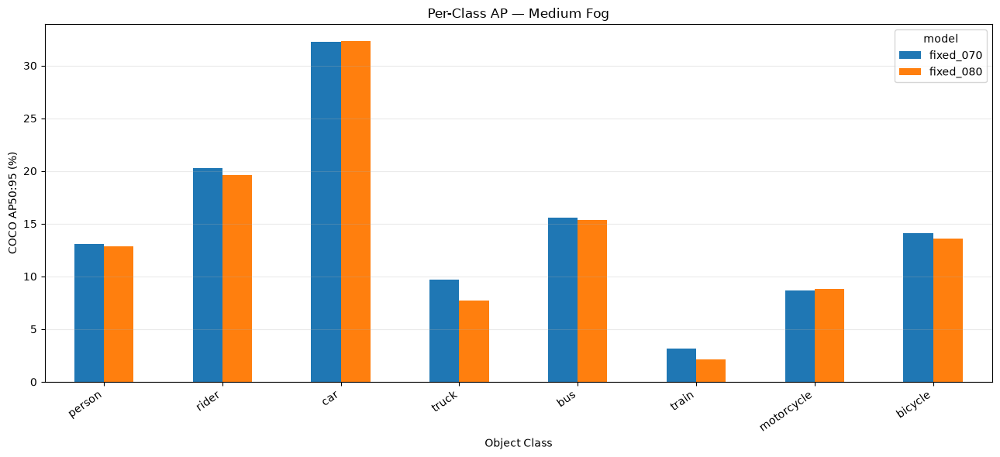

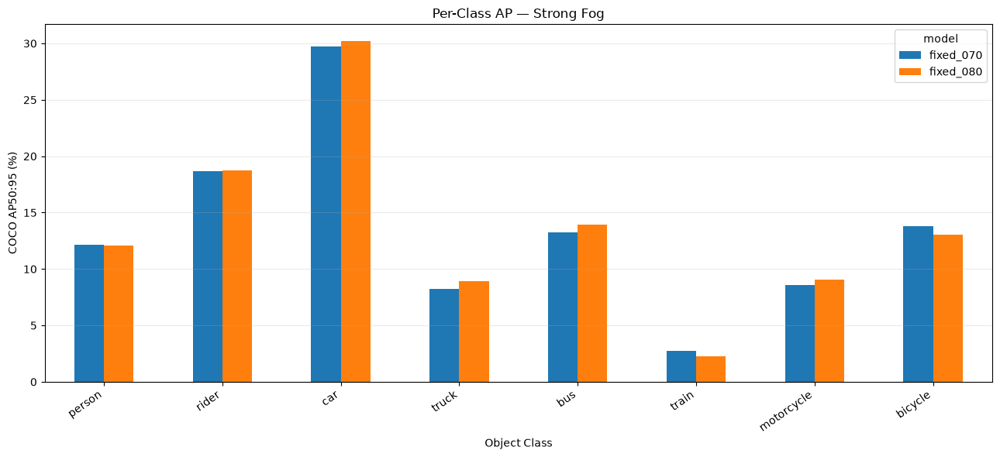


Loading 0.80 baseline teacher...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0


AssertionError: short_edge_length must be two values using 'range' sample style. Got [800]!

In [20]:

# ================================================================
# EXPERIMENT 05B — COMPLETE EVALUATION AND VISUALIZATION
# Cityscapes -> Foggy Cityscapes
# Fixed pseudo-label thresholds: 0.80 vs 0.70
# Evaluation only — NO TRAINING
# ================================================================

import os
import sys
import re
import gc
import json
import copy
import importlib
from pathlib import Path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

ROOT = Path("/workspace")
BASE = ROOT / "experiments/cityscapes_to_foggy"
DATA_ROOT = ROOT / "datasets"
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
COMPAT = BASE / "source_only/pilot_1000_v1/python_compat"

EXP03 = BASE / "fog_density_evaluation/v1"
EXP05 = BASE / "experiment_05_fog_aware_teacher"

CKPT_080 = (
    BASE / "adaptive_teacher/pilot_5000_warmstart_v2/model_final.pth"
)
CFG_080 = (
    BASE / "adaptive_teacher/pilot_5000_warmstart_v2/"
    "adaptive_teacher_5000.yaml"
)

CKPT_070 = EXP05 / "fixed_070/model_final.pth"
CFG_070 = EXP05 / "configs/fixed_070.yaml"

OUT = EXP05 / "evaluation_fixed_070"
VIS = OUT / "visualizations"
VIS.mkdir(parents=True, exist_ok=True)

for path in [CKPT_080, CFG_080, CKPT_070, CFG_070]:
    if not path.is_file():
        raise FileNotFoundError(path)

assert torch.cuda.is_available(), "CUDA GPU is unavailable."

os.environ["DETECTRON2_DATASETS"] = str(DATA_ROOT)

for folder in [str(COMPAT), str(REPO)]:
    if folder not in sys.path:
        sys.path.insert(0, folder)

print("=" * 72)
print("EXPERIMENT 05B — EVALUATION")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)

# ------------------------------------------------
# 2. DETECTRON2 IMPORTS
# ------------------------------------------------

from detectron2.config import get_cfg

from detectron2.data import (
    DatasetCatalog,
    MetadataCatalog,
    build_detection_test_loader,
)

from detectron2.data.datasets.builtin import register_all_cityscapes
from detectron2.modeling import build_model
from detectron2.modeling.backbone import BACKBONE_REGISTRY
from detectron2.modeling.meta_arch.build import META_ARCH_REGISTRY
from detectron2.modeling.proposal_generator.build import (
    PROPOSAL_GENERATOR_REGISTRY,
)
from detectron2.modeling.roi_heads import ROI_HEADS_REGISTRY

from detectron2.evaluation import (
    COCOEvaluator,
    inference_on_dataset,
)

from detectron2.data import transforms as T
from detectron2.data.detection_utils import read_image
from detectron2.utils.visualizer import Visualizer, ColorMode

from adapteacher.config import add_ateacher_config

import adapteacher.modeling
import prod_lib.modeling

# ------------------------------------------------
# 3. CONFIGURATIONS
# ------------------------------------------------

def load_config(path):
    config = get_cfg()
    add_ateacher_config(config)
    config.merge_from_file(str(path))

    config.defrost()
    config.MODEL.DEVICE = "cuda"
    config.DATALOADER.NUM_WORKERS = 0
    config.freeze()

    return config


cfg_080 = load_config(CFG_080)
cfg_070 = load_config(CFG_070)

assert abs(cfg_080.SEMISUPNET.BBOX_THRESHOLD - 0.80) < 1e-6
assert abs(cfg_070.SEMISUPNET.BBOX_THRESHOLD - 0.70) < 1e-6
assert cfg_080.SOLVER.MAX_ITER == 5000
assert cfg_070.SOLVER.MAX_ITER == 5000


def get_config_value(config, dotted_key):
    value = config
    for part in dotted_key.split("."):
        value = value[part]
    return value


inference_keys = [
    "MODEL.META_ARCHITECTURE",
    "MODEL.BACKBONE.NAME",
    "MODEL.PROPOSAL_GENERATOR.NAME",
    "MODEL.ROI_HEADS.NAME",
    "MODEL.ROI_HEADS.SCORE_THRESH_TEST",
    "MODEL.ROI_HEADS.NUM_CLASSES",
    "INPUT.FORMAT",
    "INPUT.MIN_SIZE_TEST",
    "INPUT.MAX_SIZE_TEST",
    "TEST.DETECTIONS_PER_IMAGE",
]

print("\nVALIDATING INFERENCE CONFIGURATIONS")

for key in inference_keys:
    a = get_config_value(cfg_080, key)
    b = get_config_value(cfg_070, key)

    if a != b:
        raise RuntimeError(
            f"Inference mismatch for {key}: "
            f"0.80={a}, 0.70={b}"
        )

    print(f"  {key}: {a}")

print("Inference configuration validation passed.")

# ------------------------------------------------
# 4. REGISTER CUSTOM DETECTRON2 COMPONENTS
# ------------------------------------------------

def find_and_register(name, registry):
    if name in registry._obj_map:
        return

    candidates = []

    for file in REPO.rglob("*.py"):
        try:
            content = file.read_text(errors="replace")
        except OSError:
            continue

        if re.search(
            rf"\b(?:def|class)\s+{re.escape(name)}\b",
            content
        ):
            candidates.append(file)

    if not candidates:
        raise RuntimeError(f"Implementation not found: {name}")

    for file in candidates:
        if name in registry._obj_map:
            break

        module = ".".join(
            file.relative_to(REPO).with_suffix("").parts
        )

        if module not in sys.modules:
            importlib.import_module(module)

    if name not in registry._obj_map:
        raise RuntimeError(f"Registration failed: {name}")


for config in [cfg_080, cfg_070]:
    components = [
        (config.MODEL.META_ARCHITECTURE, META_ARCH_REGISTRY),
        (config.MODEL.BACKBONE.NAME, BACKBONE_REGISTRY),
        (
            config.MODEL.PROPOSAL_GENERATOR.NAME,
            PROPOSAL_GENERATOR_REGISTRY,
        ),
        (config.MODEL.ROI_HEADS.NAME, ROI_HEADS_REGISTRY),
    ]

    for name, registry in components:
        find_and_register(name, registry)

print("\nAll custom model components registered.")

# ------------------------------------------------
# 5. REGISTER THE SAME DATASETS AS EXPERIMENT 03
# ------------------------------------------------

FOG_LEVELS = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

ORDER = list(FOG_LEVELS)

CLASSES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle",
]

SOURCE_DATASET = "cityscapes_fine_instance_seg_val"

if SOURCE_DATASET not in DatasetCatalog.list():
    register_all_cityscapes(str(DATA_ROOT))

source_records = DatasetCatalog.get(SOURCE_DATASET)
assert len(source_records) == 500


def canonical_name(filename):
    name = Path(filename).stem
    name = re.sub(r"_foggy_beta_[0-9.]+$", "", name)
    name = re.sub(r"_leftImg8bit$", "", name)
    return name


source_lookup = {
    canonical_name(record["file_name"]): record
    for record in source_records
}

assert len(source_lookup) == 500

FOG_DATASETS = {}
FOG_RECORDS = {}

for level, beta in FOG_LEVELS.items():
    dataset_name = f"cityscapes_foggy_val_{level}"

    images = sorted(
        (
            DATA_ROOT / "cityscapes_foggy/leftImg8bit/val"
        ).rglob(
            f"*_leftImg8bit_foggy_beta_{beta}.png"
        )
    )

    assert len(images) == 500, (
        f"{level}: expected 500 images, found {len(images)}"
    )

    records = []

    for image_path in images:
        key = canonical_name(image_path)

        if key not in source_lookup:
            raise KeyError(f"Annotation missing: {image_path}")

        record = copy.deepcopy(source_lookup[key])
        record["file_name"] = str(image_path)
        records.append(record)

    if dataset_name in DatasetCatalog.list():
        DatasetCatalog.remove(dataset_name)

    DatasetCatalog.register(
        dataset_name,
        lambda records=records: copy.deepcopy(records)
    )

    source_meta = MetadataCatalog.get(SOURCE_DATASET)

    MetadataCatalog.get(dataset_name).set(
        thing_classes=list(source_meta.thing_classes),
        evaluator_type="coco",
    )

    FOG_DATASETS[level] = dataset_name
    FOG_RECORDS[level] = records

    print(f"Registered {level}: {len(records)} images")

# ------------------------------------------------
# 6. LOAD TEACHER WEIGHTS
# ------------------------------------------------

def get_teacher_weights(path):
    checkpoint = torch.load(
        str(path),
        map_location="cpu",
        weights_only=False,
    )

    state = checkpoint.get("model", checkpoint)

    teacher = {
        key[len("modelTeacher."):]: value
        for key, value in state.items()
        if key.startswith("modelTeacher.")
    }

    if not teacher:
        raise RuntimeError(
            f"No modelTeacher weights found: {path}"
        )

    del checkpoint, state
    return teacher


def make_model(config, weights):
    model = build_model(config)
    expected = model.state_dict()

    missing = sorted(set(expected) - set(weights))
    unexpected = sorted(set(weights) - set(expected))

    shape_errors = [
        key for key in expected
        if key in weights
        and expected[key].shape != weights[key].shape
    ]

    print("Missing keys:", len(missing))
    print("Unexpected keys:", len(unexpected))
    print("Shape mismatches:", len(shape_errors))

    if missing or unexpected or shape_errors:
        raise RuntimeError(
            "Checkpoint/model incompatibility:\n"
            f"Missing: {missing[:10]}\n"
            f"Unexpected: {unexpected[:10]}\n"
            f"Shape errors: {shape_errors[:10]}"
        )

    model.load_state_dict(weights, strict=True)
    model.eval()
    return model


print("\nLoading threshold 0.70 teacher...")

weights_070 = get_teacher_weights(CKPT_070)
model_070 = make_model(cfg_070, weights_070)
del weights_070

print("0.70 teacher model loaded successfully.")

# ------------------------------------------------
# 7. EVALUATE THE 0.70 MODEL
# ------------------------------------------------

results_070 = []
class_results_070 = []

for level, beta in FOG_LEVELS.items():
    print("\n" + "=" * 72)
    print(f"EVALUATING THRESHOLD 0.70 — {level.upper()} FOG")
    print("=" * 72)

    dataset_name = FOG_DATASETS[level]
    result_dir = OUT / "fixed_070" / level
    result_dir.mkdir(parents=True, exist_ok=True)

    loader = build_detection_test_loader(
        cfg_070,
        dataset_name,
    )

    evaluator = COCOEvaluator(
        dataset_name,
        output_dir=str(result_dir),
    )

    with torch.inference_mode():
        metrics = inference_on_dataset(
            model_070,
            loader,
            evaluator,
        )

    bbox = metrics.get("bbox", {})

    results_070.append({
        "model": "fixed_070",
        "fog_density": level,
        "beta": float(beta),
        "AP": bbox.get("AP", np.nan),
        "AP50": bbox.get("AP50", np.nan),
        "AP75": bbox.get("AP75", np.nan),
        "APs": bbox.get("APs", np.nan),
        "APm": bbox.get("APm", np.nan),
        "APl": bbox.get("APl", np.nan),
    })

    for cls in CLASSES:
        class_results_070.append({
            "model": "fixed_070",
            "fog_density": level,
            "class": cls,
            "AP": bbox.get(f"AP-{cls}", np.nan),
        })

    with open(result_dir / "metrics.json", "w") as f:
        json.dump(metrics, f, indent=2, default=float)

    print(
        f"\n{level.upper()}: "
        f"AP50:95={bbox.get('AP', np.nan):.3f} | "
        f"AP50={bbox.get('AP50', np.nan):.3f}"
    )

    # Save intermediate results so they survive later errors
    pd.DataFrame(results_070).to_csv(
        OUT / "fixed_070_results.csv",
        index=False,
    )

    pd.DataFrame(class_results_070).to_csv(
        OUT / "fixed_070_per_class.csv",
        index=False,
    )

print("\nAll three fog densities evaluated.")

# ------------------------------------------------
# 8. LOAD EXPERIMENT 03 BASELINE RESULTS
# ------------------------------------------------

baseline_file = EXP03 / "fog_density_results.csv"
class_file = EXP03 / "per_class_results.csv"

for path in [baseline_file, class_file]:
    if not path.is_file():
        raise FileNotFoundError(path)

previous = pd.read_csv(baseline_file)

baseline = previous[
    previous["model"] == "adaptive_teacher"
].copy()

assert len(baseline) == 3
assert set(baseline["fog_density"]) == set(ORDER)

baseline["model"] = "fixed_080"

new_results = pd.DataFrame(results_070)

combined = pd.concat(
    [baseline, new_results],
    ignore_index=True,
)

combined.to_csv(
    OUT / "threshold_comparison.csv",
    index=False,
)

# ------------------------------------------------
# 9. PERFORMANCE COMPARISON TABLES
# ------------------------------------------------

comparison = combined.pivot(
    index="fog_density",
    columns="model",
    values="AP",
).reindex(ORDER)

comparison["delta_pp"] = (
    comparison["fixed_070"] - comparison["fixed_080"]
)

comparison.to_csv(OUT / "ap_comparison.csv")

comparison_ap50 = combined.pivot(
    index="fog_density",
    columns="model",
    values="AP50",
).reindex(ORDER)

comparison_ap50["delta_pp"] = (
    comparison_ap50["fixed_070"]
    - comparison_ap50["fixed_080"]
)

comparison_ap50.to_csv(OUT / "ap50_comparison.csv")

print("\n" + "=" * 72)
print("AP50:95 COMPARISON")
print("=" * 72)
display(comparison.round(3))

print("\nAP50 COMPARISON")
display(comparison_ap50.round(3))

# ------------------------------------------------
# 10. AP50:95 COMPARISON CHART
# ------------------------------------------------

x = np.arange(len(ORDER))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_080 = ax.bar(
    x - width / 2,
    comparison["fixed_080"],
    width,
    label="Threshold 0.80",
)

bars_070 = ax.bar(
    x + width / 2,
    comparison["fixed_070"],
    width,
    label="Threshold 0.70",
)

ax.bar_label(bars_080, fmt="%.2f", padding=3)
ax.bar_label(bars_070, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["Light", "Medium", "Strong"])
ax.set_xlabel("Fog Density")
ax.set_ylabel("COCO AP50:95 (%)")
ax.set_title("Experiment 05B — Pseudo-Label Threshold Ablation")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(VIS / "01_ap_comparison.png", dpi=200)
plt.show()

# ------------------------------------------------
# 11. AP50 COMPARISON CHART
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

bars_080 = ax.bar(
    x - width / 2,
    comparison_ap50["fixed_080"],
    width,
    label="Threshold 0.80",
)

bars_070 = ax.bar(
    x + width / 2,
    comparison_ap50["fixed_070"],
    width,
    label="Threshold 0.70",
)

ax.bar_label(bars_080, fmt="%.2f", padding=3)
ax.bar_label(bars_070, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["Light", "Medium", "Strong"])
ax.set_xlabel("Fog Density")
ax.set_ylabel("COCO AP50 (%)")
ax.set_title("AP50 — Threshold 0.80 vs 0.70")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(VIS / "02_ap50_comparison.png", dpi=200)
plt.show()

# ------------------------------------------------
# 12. FOG DEGRADATION CHART
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for column, label in [
    ("fixed_080", "Threshold 0.80"),
    ("fixed_070", "Threshold 0.70"),
]:
    ax.plot(
        ["Light", "Medium", "Strong"],
        comparison[column].values,
        marker="o",
        linewidth=2,
        label=label,
    )

ax.set_xlabel("Fog Density")
ax.set_ylabel("COCO AP50:95 (%)")
ax.set_title("Detection Performance Under Increasing Fog")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(VIS / "03_fog_degradation.png", dpi=200)
plt.show()

# ------------------------------------------------
# 13. THRESHOLD EFFECT CHART
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    ["Light", "Medium", "Strong"],
    comparison["delta_pp"].values,
)

ax.axhline(0, color="black", linewidth=1)
ax.bar_label(bars, fmt="%+.2f", padding=3)

ax.set_xlabel("Fog Density")
ax.set_ylabel("AP50:95 Difference (percentage points)")
ax.set_title("Effect of Reducing Pseudo-Label Threshold")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(VIS / "04_threshold_effect.png", dpi=200)
plt.show()

# ------------------------------------------------
# 14. PER-CLASS AP CHARTS
# ------------------------------------------------

previous_classes = pd.read_csv(class_file)

baseline_classes = previous_classes[
    previous_classes["model"] == "adaptive_teacher"
].copy()

baseline_classes["model"] = "fixed_080"

all_classes = pd.concat(
    [
        baseline_classes,
        pd.DataFrame(class_results_070),
    ],
    ignore_index=True,
)

all_classes.to_csv(
    OUT / "per_class_comparison.csv",
    index=False,
)

for level in ORDER:
    subset = all_classes[
        all_classes["fog_density"] == level
    ]

    pivot = subset.pivot(
        index="class",
        columns="model",
        values="AP",
    ).reindex(CLASSES)

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 6),
    )

    ax.set_title(f"Per-Class AP — {level.title()} Fog")
    ax.set_xlabel("Object Class")
    ax.set_ylabel("COCO AP50:95 (%)")
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(
        VIS / f"05_per_class_{level}.png",
        dpi=200,
    )

    plt.show()

# ------------------------------------------------
# 15. LOAD BASELINE MODEL FOR DETECTION VISUALIZATION
# ------------------------------------------------

print("\nLoading 0.80 baseline teacher...")

weights_080 = get_teacher_weights(CKPT_080)
model_080 = make_model(cfg_080, weights_080)
del weights_080

metadata = MetadataCatalog.get(SOURCE_DATASET)

# ------------------------------------------------
# 16. DETECTION PREDICTION AND DRAWING
# ------------------------------------------------

def predict_image(model, config, image_path):
    image = read_image(
        str(image_path),
        format=config.INPUT.FORMAT,
    )

    height, width = image.shape[:2]

    augmentation = T.ResizeShortestEdge(
        [config.INPUT.MIN_SIZE_TEST],
        config.INPUT.MAX_SIZE_TEST,
        sample_style="choice"
    )

    transformed = (
        augmentation.get_transform(image).apply_image(image)
    )

    tensor = torch.as_tensor(
        np.ascontiguousarray(
            transformed.transpose(2, 0, 1)
        ).astype("float32")
    ).to(config.MODEL.DEVICE)

    with torch.inference_mode():
        outputs = model([{
            "image": tensor,
            "height": height,
            "width": width,
        }])

    return outputs[0]["instances"].to("cpu")


def draw_predictions(image_path, predictions, threshold=0.50):
    image_bgr = read_image(str(image_path), format="BGR")
    image_rgb = image_bgr[:, :, ::-1]

    filtered = predictions[
        predictions.scores >= threshold
    ]

    visualizer = Visualizer(
        image_rgb,
        metadata=metadata,
        scale=0.65,
        instance_mode=ColorMode.IMAGE,
    )

    rendered = visualizer.draw_instance_predictions(filtered)
    return rendered.get_image(), len(filtered)

# ------------------------------------------------
# 17. SIDE-BY-SIDE DETECTION VISUALIZATIONS
# ------------------------------------------------

SAMPLES_PER_LEVEL = 3
DISPLAY_THRESHOLD = 0.50

for level in ORDER:
    records = FOG_RECORDS[level]

    indices = np.linspace(
        0,
        len(records) - 1,
        SAMPLES_PER_LEVEL,
        dtype=int,
    )

    for sample_number, idx in enumerate(indices, start=1):
        image_path = Path(records[idx]["file_name"])

        predictions_080 = predict_image(
            model_080, cfg_080, image_path
        )

        predictions_070 = predict_image(
            model_070, cfg_070, image_path
        )

        image_080, count_080 = draw_predictions(
            image_path, predictions_080, DISPLAY_THRESHOLD
        )

        image_070, count_070 = draw_predictions(
            image_path, predictions_070, DISPLAY_THRESHOLD
        )

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))

        axes[0].imshow(image_080)
        axes[0].set_title(
            f"Threshold 0.80 — {count_080} detections"
        )
        axes[0].axis("off")

        axes[1].imshow(image_070)
        axes[1].set_title(
            f"Threshold 0.70 — {count_070} detections"
        )
        axes[1].axis("off")

        fig.suptitle(
            f"{level.title()} Fog | {image_path.stem}",
            fontsize=13,
        )

        plt.tight_layout()

        plt.savefig(
            VIS / f"06_detections_{level}_{sample_number}.png",
            dpi=160,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

# ------------------------------------------------
# 18. SAVE SUMMARY
# ------------------------------------------------

summary = {
    "experiment": "Experiment 05B",
    "description": "Fixed 0.80 vs fixed 0.70 threshold ablation",
    "source": "Cityscapes",
    "target": "Foggy Cityscapes",
    "training_iterations": 5000,
    "evaluation_branch": "modelTeacher",
    "images_per_fog_level": 500,
    "fog_levels": FOG_LEVELS,
    "results": combined.to_dict(orient="records"),
    "comparison": comparison.reset_index().to_dict(
        orient="records"
    ),
}

with open(OUT / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)

del model_080, model_070
gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 72)
print("EXPERIMENT 05B COMPLETE")
print("=" * 72)

print("Results:", OUT)
print("Visualizations:", VIS)

print("\nFINAL AP50:95 COMPARISON")
display(comparison.round(3))

print("\nFINAL AP50 COMPARISON")
display(comparison_ap50.round(3))


Processing LIGHT fog sample 1/3


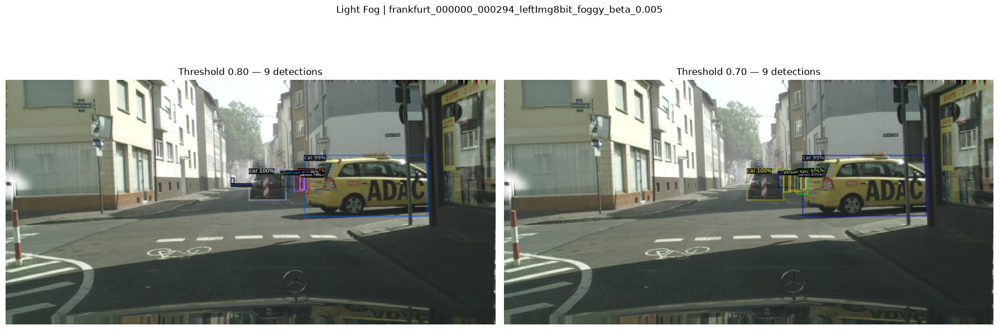

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_light_1.png
Processing LIGHT fog sample 2/3


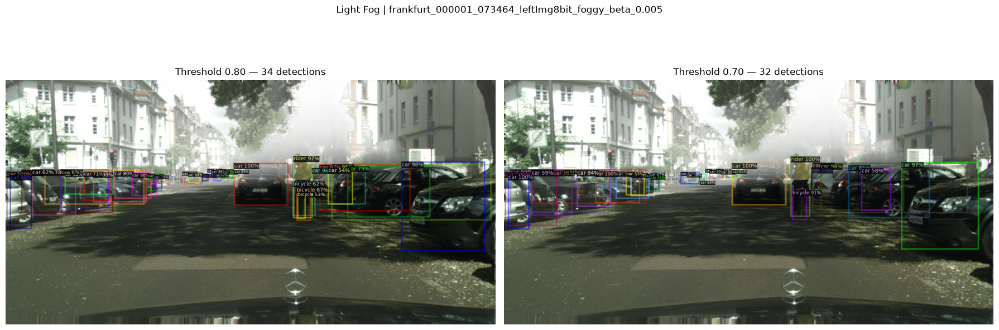

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_light_2.png
Processing LIGHT fog sample 3/3


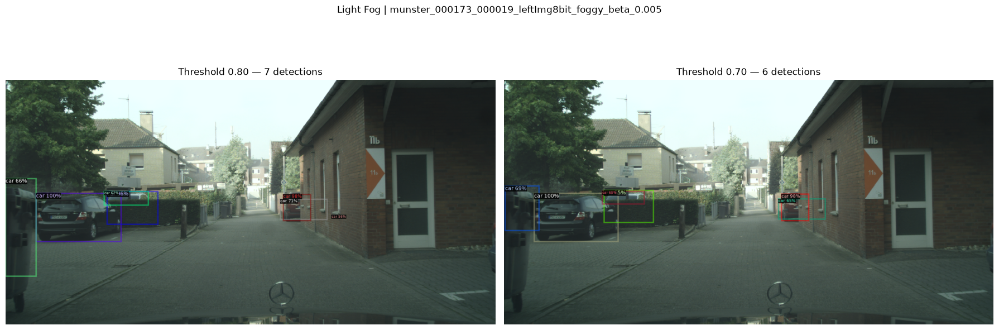

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_light_3.png
Processing MEDIUM fog sample 1/3


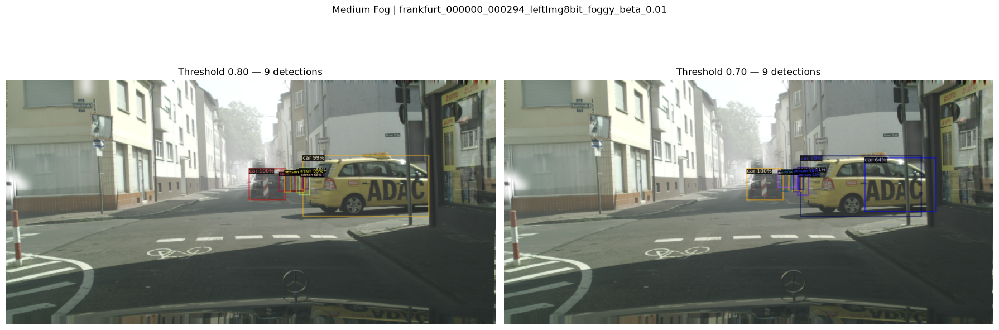

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_medium_1.png
Processing MEDIUM fog sample 2/3


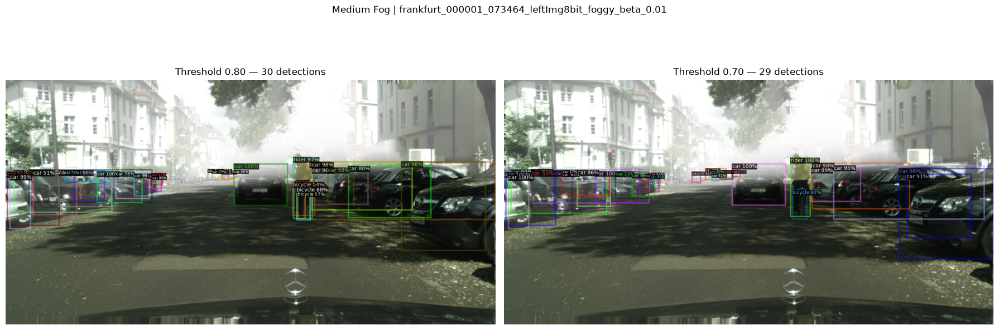

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_medium_2.png
Processing MEDIUM fog sample 3/3


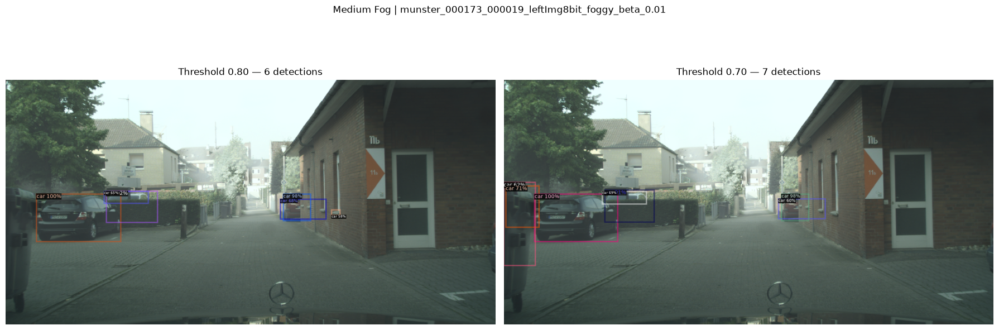

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_medium_3.png
Processing STRONG fog sample 1/3


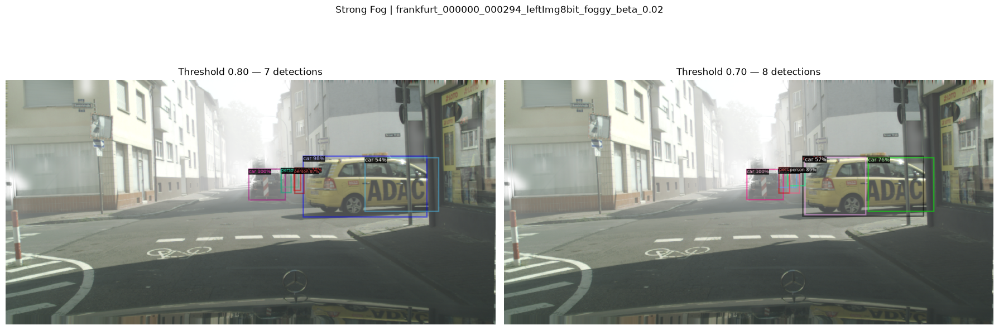

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_strong_1.png
Processing STRONG fog sample 2/3


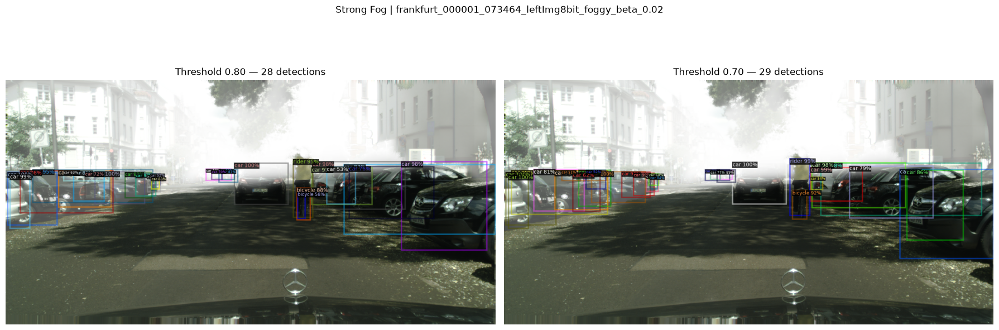

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_strong_2.png
Processing STRONG fog sample 3/3


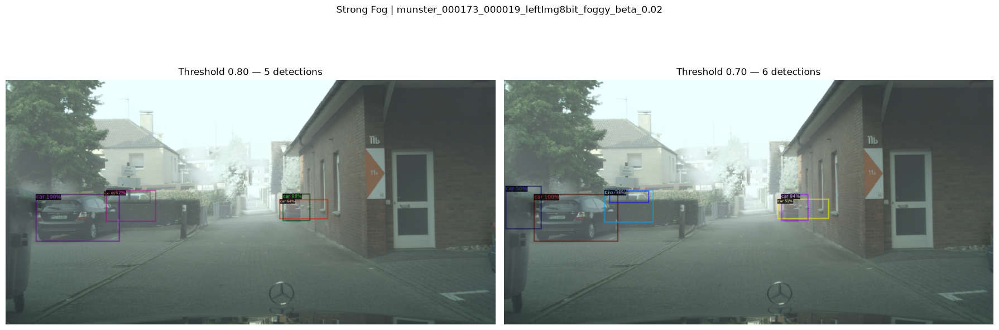

Saved: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations/06_detections_strong_3.png

EXPERIMENT 05B VISUALIZATIONS COMPLETED
Output folder: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/evaluation_fixed_070/visualizations


In [21]:

# ============================================================
# EXPERIMENT 05B — RESUME VISUALIZATIONS ONLY
# Does NOT repeat training or evaluation
# ============================================================

# Verify existing objects are still in memory
required = [
    "model_080", "model_070",
    "cfg_080", "cfg_070",
    "FOG_RECORDS", "ORDER",
    "VIS", "metadata"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing notebook variables: {missing}. "
        "The kernel may have been restarted."
    )

# ------------------------------------------------------------
# FIX THE PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_image(model, config, image_path):

    image = read_image(
        str(image_path),
        format=config.INPUT.FORMAT
    )

    height, width = image.shape[:2]

    # Fixed preprocessing compatible with your Detectron2
    augmentation = T.ResizeShortestEdge(
        short_edge_length=[
            config.INPUT.MIN_SIZE_TEST,
            config.INPUT.MIN_SIZE_TEST
        ],
        max_size=config.INPUT.MAX_SIZE_TEST,
        sample_style="choice"
    )

    transformed = augmentation.get_transform(
        image
    ).apply_image(image)

    tensor = torch.as_tensor(
        np.ascontiguousarray(
            transformed.transpose(2, 0, 1)
        ).astype("float32")
    ).to(config.MODEL.DEVICE)

    with torch.inference_mode():
        outputs = model([{
            "image": tensor,
            "height": height,
            "width": width
        }])

    return outputs[0]["instances"].to("cpu")


# ------------------------------------------------------------
# GENERATE SIDE-BY-SIDE VISUALIZATIONS
# ------------------------------------------------------------

SAMPLES_PER_LEVEL = 3
DISPLAY_THRESHOLD = 0.50

for level in ORDER:

    records = FOG_RECORDS[level]

    indices = np.linspace(
        0,
        len(records) - 1,
        SAMPLES_PER_LEVEL,
        dtype=int
    )

    for sample_number, idx in enumerate(indices, start=1):

        image_path = Path(records[idx]["file_name"])

        print(
            f"Processing {level.upper()} fog "
            f"sample {sample_number}/{SAMPLES_PER_LEVEL}"
        )

        predictions_080 = predict_image(
            model_080, cfg_080, image_path
        )

        predictions_070 = predict_image(
            model_070, cfg_070, image_path
        )

        image_080, count_080 = draw_predictions(
            image_path, predictions_080, DISPLAY_THRESHOLD
        )

        image_070, count_070 = draw_predictions(
            image_path, predictions_070, DISPLAY_THRESHOLD
        )

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))

        axes[0].imshow(image_080)
        axes[0].set_title(
            f"Threshold 0.80 — {count_080} detections"
        )
        axes[0].axis("off")

        axes[1].imshow(image_070)
        axes[1].set_title(
            f"Threshold 0.70 — {count_070} detections"
        )
        axes[1].axis("off")

        fig.suptitle(
            f"{level.title()} Fog | {image_path.stem}"
        )

        plt.tight_layout()

        output_path = (
            VIS / f"06_detections_{level}_{sample_number}.png"
        )

        plt.savefig(
            output_path,
            dpi=160,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

        print("Saved:", output_path)

print("\nEXPERIMENT 05B VISUALIZATIONS COMPLETED")
print("Output folder:", VIS)


In [23]:

# ============================================================
# EXPERIMENT 05C — FOG-AWARE IMPLEMENTATION PREPARATION
# READ-ONLY: No source modifications or training
# ============================================================

from pathlib import Path
import ast
import re
import json

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
OUT = (
    ROOT / "experiments/cityscapes_to_foggy"
    / "experiment_05_fog_aware_teacher"
    / "experiment_05c_inspection"
)

OUT.mkdir(parents=True, exist_ok=True)

TARGETS = {
    "trainer": REPO / "adapteacher/engine/trainer.py",
    "data_loader": REPO / "adapteacher/data/build.py",
}

SEARCH_PATTERNS = [
    r"def\s+run_step_full_semisup",
    r"def\s+threshold_bbox",
    r"def\s+process_pseudo_label",
    r"def\s+add_label",
    r"def\s+remove_label",
    r"unlabel_data_k",
    r"unlabel_data_q",
    r"file_name",
    r"image_id",
    r"DatasetMapper",
    r"TwoCrop",
    r"build_detection_semisup_train_loader",
]

report = []

print("=" * 75)
print("EXPERIMENT 05C — IMPLEMENTATION PREPARATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Inspect the exact trainer functions
# ------------------------------------------------------------

trainer_path = TARGETS["trainer"]

if not trainer_path.exists():
    raise FileNotFoundError(trainer_path)

source = trainer_path.read_text(errors="replace")
lines = source.splitlines()
tree = ast.parse(source)

FUNCTIONS = {
    "run_step_full_semisup",
    "threshold_bbox",
    "process_pseudo_label",
    "add_label",
    "remove_label",
}

for node in ast.walk(tree):
    if not isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        continue

    if node.name not in FUNCTIONS:
        continue

    content = "\n".join(
        f"{i + 1:04d}: {lines[i]}"
        for i in range(node.lineno - 1, node.end_lineno)
    )

    report.append(
        {
            "type": "function",
            "name": node.name,
            "file": str(trainer_path),
            "start": node.lineno,
            "end": node.end_lineno,
            "content": content,
        }
    )

    print(
        f"\nFOUND: {node.name} "
        f"(lines {node.lineno}-{node.end_lineno})"
    )

# ------------------------------------------------------------
# 2. Inspect data-loader and mapper implementations
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DATA PIPELINE SEARCH")
print("=" * 75)

data_files = [
    p for p in REPO.rglob("*.py")
    if "data" in p.parts or "mapper" in p.name.lower()
]

data_matches = []

for path in data_files:
    text = path.read_text(errors="replace")
    file_lines = text.splitlines()

    for i, line in enumerate(file_lines):
        if any(
            re.search(pattern, line)
            for pattern in SEARCH_PATTERNS
        ):
            data_matches.append(
                {
                    "file": str(path.relative_to(REPO)),
                    "line": i + 1,
                    "source": line.strip(),
                }
            )

for item in data_matches[:80]:
    print(
        f"{item['file']}:{item['line']} "
        f"{item['source']}"
    )

print("\nTotal data pipeline matches:", len(data_matches))

# ------------------------------------------------------------
# 3. Inspect the existing fog image filenames
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FOG METADATA VERIFICATION")
print("=" * 75)

FOG_DIR = (
    ROOT / "datasets/cityscapes_foggy/leftImg8bit/train"
)

fog_patterns = {
    "light": "_foggy_beta_0.005.png",
    "medium": "_foggy_beta_0.01.png",
    "strong": "_foggy_beta_0.02.png",
}

fog_samples = {}

for level, suffix in fog_patterns.items():
    images = sorted(FOG_DIR.rglob(f"*{suffix}"))

    fog_samples[level] = {
        "count": len(images),
        "example": str(images[0]) if images else None,
    }

    print(
        f"{level.upper():8} "
        f"images={len(images)}"
    )

    if images:
        print(" Example:", images[0].name)

# ------------------------------------------------------------
# 4. Verify source/target dataset settings
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING CONFIGURATION")
print("=" * 75)

import yaml

CONFIG = (
    ROOT / "experiments/cityscapes_to_foggy"
    / "experiment_05_fog_aware_teacher"
    / "configs/fixed_070.yaml"
)

with open(CONFIG) as f:
    cfg = yaml.safe_load(f)

for section in [
    "DATASETS",
    "DATALOADER",
    "SEMISUPNET",
    "SOLVER",
]:
    print(f"\n{section}:")
    print(json.dumps(cfg.get(section, {}), indent=2, default=str))

# ------------------------------------------------------------
# 5. Save complete inspection report
# ------------------------------------------------------------

output = OUT / "fog_aware_implementation_preparation.txt"

with open(output, "w") as f:
    f.write("EXPERIMENT 05C IMPLEMENTATION PREPARATION\n\n")

    for item in report:
        f.write("\n" + "=" * 80 + "\n")
        f.write(
            f"{item['name']} — "
            f"{item['file']} "
            f"({item['start']}-{item['end']})\n"
        )
        f.write("=" * 80 + "\n")
        f.write(item["content"] + "\n")

    f.write("\nDATA PIPELINE MATCHES\n")

    for item in data_matches:
        f.write(
            f"{item['file']}:{item['line']} "
            f"{item['source']}\n"
        )

    f.write("\nFOG IMAGE SAMPLES\n")
    f.write(json.dumps(fog_samples, indent=2))

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("=" * 75)
print("Report saved to:", output)
print("Trainer functions found:", len(report))
print("Data pipeline matches:", len(data_matches))


EXPERIMENT 05C — IMPLEMENTATION PREPARATION

FOUND: threshold_bbox (lines 420-453)

FOUND: process_pseudo_label (lines 455-471)

FOUND: remove_label (lines 473-477)

FOUND: add_label (lines 479-482)

FOUND: run_step_full_semisup (lines 502-665)

DATA PIPELINE SEARCH
adapteacher/data/__init__.py:4 build_detection_semisup_train_loader,
adapteacher/data/build.py:12 from detectron2.data.dataset_mapper import DatasetMapper
adapteacher/data/build.py:25 AspectRatioGroupedSemiSupDatasetTwoCrop,
adapteacher/data/build.py:61 def build_detection_semisup_train_loader(cfg, mapper=None):
adapteacher/data/build.py:85 mapper = DatasetMapper(cfg, True)
adapteacher/data/build.py:132 mapper = DatasetMapper(cfg, False)
adapteacher/data/build.py:148 def build_detection_semisup_train_loader_two_crops(cfg, mapper=None):
adapteacher/data/build.py:197 mapper = DatasetMapper(cfg, True)
adapteacher/data/build.py:271 return AspectRatioGroupedSemiSupDatasetTwoCrop(
adapteacher/data/common.py:6 class MapDatasetTwoC

In [31]:

from pathlib import Path
import os
import sys
import yaml
import subprocess
import re
import time

ROOT = Path("/workspace")

WORK = (
    ROOT / "experiments/cityscapes_to_foggy"
    / "experiment_05_fog_aware_teacher/fog_aware_05c"
)

CODE = ROOT / "fog_aware_05c_code"
CONFIG = WORK / "configs/fog_aware_smoke.yaml"
LOG = WORK / "logs/smoke_test.log"

COMPAT = (
    ROOT / "experiments/cityscapes_to_foggy"
    / "source_only/pilot_1000_v1/python_compat"
)

assert (CODE / "train_net.py").exists()
assert CONFIG.exists()

with CONFIG.open() as f:
    cfg = yaml.safe_load(f)

print("=" * 70)
print("EXPERIMENT 05C — SMOKE TEST")
print("=" * 70)

print("\nConfiguration:")
print("Target dataset:", cfg["DATASETS"].get("TRAIN_UNLABEL"))
print("Source dataset:", cfg["DATASETS"].get("TRAIN_LABEL"))
print("Iterations:", cfg["SOLVER"]["MAX_ITER"])
print("Burn-in:", cfg["SEMISUPNET"]["BURN_UP_STEP"])

assert cfg["SOLVER"]["MAX_ITER"] == 3
assert cfg["SEMISUPNET"]["BURN_UP_STEP"] == 1

# Verify the configured target dataset name.
target_names = cfg["DATASETS"].get("TRAIN_UNLABEL", [])

assert target_names, (
    "No unlabeled target dataset configured."
)

print("\nExpected fog thresholds:")
print("Light: 0.80")
print("Medium: 0.70")
print("Strong: 0.80")

# Prepare environment.
env = os.environ.copy()

paths = []

if COMPAT.exists():
    paths.append(str(COMPAT))

paths.append(str(CODE))

if env.get("PYTHONPATH"):
    paths.append(env["PYTHONPATH"])

env["PYTHONPATH"] = os.pathsep.join(paths)
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONUNBUFFERED"] = "1"

# Start smoke test.
command = [
    sys.executable,
    "-u",
    str(CODE / "train_net.py"),
    "--config-file",
    str(CONFIG),
    "--num-gpus",
    "1"
]

print("\nStarting three-iteration smoke test...")
print("Log:", LOG)

LOG.parent.mkdir(parents=True, exist_ok=True)

start = time.time()

try:
    with LOG.open("w") as log_file:
        result = subprocess.run(
            command,
            cwd=str(CODE),
            env=env,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            timeout=1800
        )

    elapsed = time.time() - start

    print("\nElapsed:", round(elapsed, 1), "seconds")
    print("Exit code:", result.returncode)

except subprocess.TimeoutExpired:
    print("\nSmoke test exceeded 30 minutes.")
    print("Check the log for dataset-loading delays.")
    result = None

print("\nLAST LOG OUTPUT:\n")

if LOG.exists():
    print(LOG.read_text(errors="replace")[-15000:])

if result is not None and result.returncode == 0:
    print("\nSMOKE TEST PASSED")
    print("Ready for full 5000-iteration training.")
else:
    print("\nSMOKE TEST NOT YET PASSED")
    print("Review the log before full training.")


EXPERIMENT 05C — SMOKE TEST

Configuration:
Target dataset: ['cityscapes_foggy_train']
Source dataset: ['cityscapes_fine_instance_seg_train']
Iterations: 3
Burn-in: 1

Expected fog thresholds:
Light: 0.80
Medium: 0.70
Strong: 0.80

Starting three-iteration smoke test...
Log: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/fog_aware_05c/logs/smoke_test.log

Elapsed: 1652.3 seconds
Exit code: 0

LAST LOG OUTPUT:

.0406 s/iter. Eval: 0.0002 s/iter. Total: 0.3559 s/iter. ETA=0:06:08
[10/13 03:38:12 d2.evaluation.evaluator]: Inference done 477/1500. Dataloading: 0.3160 s/iter. Inference: 0.0406 s/iter. Eval: 0.0002 s/iter. Total: 0.3569 s/iter. ETA=0:06:05
[10/13 03:38:17 d2.evaluation.evaluator]: Inference done 491/1500. Dataloading: 0.3163 s/iter. Inference: 0.0406 s/iter. Eval: 0.0002 s/iter. Total: 0.3572 s/iter. ETA=0:06:00
[10/13 03:38:23 d2.evaluation.evaluator]: Inference done 504/1500. Dataloading: 0.3179 s/iter. Inference: 0.0406 s/iter. Eval: 0.0002 s/i

In [41]:

from pathlib import Path
import os
import sys
import yaml
import subprocess
import time
import re
import json
import shlex
import threading
import queue
from collections import Counter

# ============================================================
# EXPERIMENT 05C — FOG-AWARE ADAPTIVE TEACHER
# FULL TRAINING: 5000 ITERATIONS — FOREGROUND
# ============================================================

ROOT = Path("/workspace")

WORK = (
    ROOT
    / "experiments/cityscapes_to_foggy"
    / "experiment_05_fog_aware_teacher"
    / "fog_aware_05c"
)

CODE = ROOT / "fog_aware_05c_code"

SOURCE_CONFIG = WORK / "configs/fog_aware_5000.yaml"

RUN_DIR = WORK / "training_5000_v2"
RUN_CONFIG = RUN_DIR / "config.yaml"
LOG = RUN_DIR / "training.log"

COMPAT = (
    ROOT
    / "experiments/cityscapes_to_foggy"
    / "source_only/pilot_1000_v1/python_compat"
)

print("=" * 75, flush=True)
print("EXPERIMENT 05C — FULL FOREGROUND TRAINING", flush=True)
print("=" * 75, flush=True)

# ============================================================
# 1. VERIFY CODE AND CONFIGURATION
# ============================================================

assert (CODE / "train_net.py").exists(), (
    "Missing train_net.py"
)

trainer_file = CODE / "adapteacher/engine/trainer.py"

assert trainer_file.exists(), (
    "Missing fog-aware trainer.py"
)

assert SOURCE_CONFIG.exists(), (
    f"Missing training config: {SOURCE_CONFIG}"
)

trainer_source = trainer_file.read_text()

compile(
    trainer_source,
    str(trainer_file),
    "exec"
)

assert "def fog_threshold_05c(" in trainer_source, (
    "Fog-aware threshold function not found"
)

assert "fog_threshold_05c(record)" in trainer_source, (
    "Fog-aware threshold function call not found"
)

assert "thres=image_threshold" in trainer_source, (
    "Per-image threshold application not found"
)

with SOURCE_CONFIG.open() as f:
    cfg = yaml.safe_load(f)

assert cfg["SOLVER"]["MAX_ITER"] == 5000
assert cfg["SEMISUPNET"]["BURN_UP_STEP"] == 1000

assert (
    "cityscapes_fine_instance_seg_train"
    in cfg["DATASETS"]["TRAIN_LABEL"]
)

assert (
    "cityscapes_foggy_train"
    in cfg["DATASETS"]["TRAIN_UNLABEL"]
)

weights = Path(cfg["MODEL"]["WEIGHTS"])

assert weights.exists(), (
    f"Initialization checkpoint missing: {weights}"
)

print("\n[PASS] Code and configuration verified")
print("Iterations:", cfg["SOLVER"]["MAX_ITER"])
print("Burn-in:", cfg["SEMISUPNET"]["BURN_UP_STEP"])
print("Initialization:", weights)

# ============================================================
# 2. VERIFY FOG DENSITY IMAGES
# ============================================================

FOG_ROOT = (
    ROOT
    / "datasets/cityscapes_foggy"
    / "leftImg8bit/train"
)

assert FOG_ROOT.exists(), (
    f"Foggy dataset missing: {FOG_ROOT}"
)

fog_pattern = re.compile(
    r"_foggy_beta_(0\.005|0\.01|0\.02)\.png$"
)

fog_counts = Counter()

for image_path in FOG_ROOT.rglob("*.png"):
    match = fog_pattern.search(image_path.name)

    if match:
        fog_counts[match.group(1)] += 1

print("\nFog density distribution:")

for beta in ["0.005", "0.01", "0.02"]:
    print(
        f"  beta={beta}: {fog_counts[beta]} images"
    )

assert all(
    fog_counts[beta] == 2975
    for beta in ["0.005", "0.01", "0.02"]
), "Foggy image counts do not match expected values"

print("[PASS] Fog-density files verified")

# ============================================================
# 3. VERIFY GPU
# ============================================================

import torch

assert torch.cuda.is_available(), (
    "CUDA GPU unavailable"
)

gpu_name = torch.cuda.get_device_name(0)

free_bytes, total_bytes = torch.cuda.mem_get_info()

free_gib = free_bytes / (1024 ** 3)
total_gib = total_bytes / (1024 ** 3)

print("\nGPU:", gpu_name)
print(f"Free GPU memory: {free_gib:.2f} GiB")
print(f"Total GPU memory: {total_gib:.2f} GiB")

assert free_gib >= 19.0, (
    "Insufficient GPU memory for a fresh training run"
)

# ============================================================
# 4. PREVENT ACCIDENTAL OVERWRITE
# ============================================================

RUN_DIR.mkdir(parents=True, exist_ok=True)

existing = [
    RUN_DIR / "training.log",
    RUN_DIR / "last_checkpoint",
    RUN_DIR / "model_final.pth",
    RUN_DIR / "config.yaml",
]

assert not any(p.exists() for p in existing), (
    "training_5000_v2 already contains experiment files. "
    "Inspect the directory before restarting."
)

# ============================================================
# 5. SAVE CONFIGURATION
# ============================================================

cfg["OUTPUT_DIR"] = str(RUN_DIR)

with RUN_CONFIG.open("w") as f:
    yaml.safe_dump(
        cfg,
        f,
        sort_keys=False
    )

manifest = {
    "experiment": "05C",
    "method": "Fog-Aware Adaptive Teacher",
    "iterations": 5000,
    "burn_in": 1000,
    "thresholds": {
        "light": 0.80,
        "medium": 0.70,
        "strong": 0.80
    },
    "source_dataset": cfg["DATASETS"]["TRAIN_LABEL"],
    "target_dataset": cfg["DATASETS"]["TRAIN_UNLABEL"],
    "initialization": str(weights),
    "output_dir": str(RUN_DIR),
    "start_time": time.strftime("%Y-%m-%d %H:%M:%S")
}

with (RUN_DIR / "manifest.json").open("w") as f:
    json.dump(manifest, f, indent=2)

print("\n[PASS] Configuration saved")
print("Output directory:", RUN_DIR)

# ============================================================
# 6. SET ENVIRONMENT
# ============================================================

env = os.environ.copy()

python_paths = []

if COMPAT.exists():
    python_paths.append(str(COMPAT))

python_paths.append(str(CODE))

if env.get("PYTHONPATH"):
    python_paths.append(env["PYTHONPATH"])

env["PYTHONPATH"] = os.pathsep.join(python_paths)

env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONUNBUFFERED"] = "1"

# ============================================================
# 7. BUILD TRAINING COMMAND
# ============================================================

command = [
    sys.executable,
    "-u",
    str(CODE / "train_net.py"),
    "--config-file",
    str(RUN_CONFIG),
    "--num-gpus",
    "1"
]

print("\nTraining command:")
print(shlex.join(command))

print("\n" + "=" * 75)
print("STARTING 5000-ITERATION TRAINING")
print("=" * 75)

print("\nTraining logs will appear below.")
print("Keep the RunPod pod running.\n", flush=True)

# ============================================================
# 8. RUN TRAINING IN FOREGROUND
# ============================================================

start_time = time.time()

process = None
return_code = None

try:
    with LOG.open("w", buffering=1) as log_file:

        process = subprocess.Popen(
            command,
            cwd=str(CODE),
            env=env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1
        )

        (RUN_DIR / "training.pid").write_text(
            str(process.pid)
        )

        print(
            f"Training PID: {process.pid}",
            flush=True
        )

        for line in process.stdout:

            log_file.write(line)

            clean_line = re.sub(
                r"\x1b\[[0-9;]*m",
                "",
                line
            ).rstrip()

            # Display meaningful progress rather than
            # thousands of configuration/model lines.
            show = any(
                keyword in clean_line
                for keyword in [
                    "iter:",
                    "Loading from",
                    "Loaded ",
                    "Evaluation results",
                    "copypaste:",
                    "Saving checkpoint",
                    "Traceback",
                    "RuntimeError",
                    "CUDA out of memory",
                    "ERROR",
                    "Error"
                ]
            )

            if show:
                print(clean_line, flush=True)

        return_code = process.wait()

except KeyboardInterrupt:

    print("\n\nINTERRUPT REQUESTED", flush=True)

    if process is not None and process.poll() is None:
        print(
            "Requesting training shutdown...",
            flush=True
        )

        process.terminate()

        try:
            process.wait(timeout=30)

        except subprocess.TimeoutExpired:
            print(
                "Training has not exited. "
                "Check the process before restarting.",
                flush=True
            )

    raise

# ============================================================
# 9. FINAL STATUS
# ============================================================

elapsed = time.time() - start_time

print("\n" + "=" * 75)
print("EXPERIMENT 05C — FINAL STATUS")
print("=" * 75)

print(
    f"Elapsed time: {elapsed / 3600:.2f} hours"
)

print("Exit code:", return_code)

checkpoint = RUN_DIR / "model_final.pth"

if return_code == 0:

    print("\nTRAINING PROCESS COMPLETED SUCCESSFULLY")

    if checkpoint.exists():
        print(
            "Final checkpoint:",
            checkpoint
        )
    else:
        print(
            "WARNING: Final checkpoint not found. "
            "Inspect training logs and saved checkpoints."
        )

else:

    print("\nTRAINING FAILED OR WAS INTERRUPTED")

    print("\nLast 30 log lines:")

    if LOG.exists():
        lines = LOG.read_text(
            errors="replace"
        ).splitlines()

        print("\n".join(lines[-30:]))

print("\nExperiment directory:", RUN_DIR)


EXPERIMENT 05C — FULL FOREGROUND TRAINING

[PASS] Code and configuration verified
Iterations: 5000
Burn-in: 1000
Initialization: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_v1/source_only_teacher_student_init.pth

Fog density distribution:
  beta=0.005: 2975 images
  beta=0.01: 2975 images
  beta=0.02: 2975 images
[PASS] Fog-density files verified

GPU: NVIDIA RTX PRO 4000 Blackwell
Free GPU memory: 21.65 GiB
Total GPU memory: 23.43 GiB

[PASS] Configuration saved
Output directory: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/fog_aware_05c/training_5000_v2

Training command:
/usr/local/bin/python -u /workspace/fog_aware_05c_code/train_net.py --config-file /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/fog_aware_05c/training_5000_v2/config.yaml --num-gpus 1

STARTING 5000-ITERATION TRAINING

Training logs will appear below.
Keep the RunPod pod running.

Training PID: 52618
[10/13 05:08:23 d2.data.datase

In [43]:

# ================================================================
# STEPS 4 AND 5 — FIXED FOG-DENSITY DATASET REGISTRATION
# ================================================================

print("\n[4/8] CHECKING EXISTING DATASET")

import adapteacher.data.datasets.builtin

BASE_DATASET = "cityscapes_foggy_val"

assert BASE_DATASET in DatasetCatalog.list(), (
    f"Dataset not registered: {BASE_DATASET}"
)

base_records = DatasetCatalog.get(BASE_DATASET)

print("Base dataset:", BASE_DATASET)
print("Total records:", len(base_records))

assert len(base_records) == 1500, (
    f"Expected 1500 images, found {len(base_records)}"
)

print("\n[5/8] SPLITTING BY FOG DENSITY")

BETA_VALUES = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

registered_fog_datasets = {}

for severity, beta in BETA_VALUES.items():

    dataset_name = f"exp05c_fog_{severity}_val"

    filtered_records = []

    suffix = f"_foggy_beta_{beta}.png"

    for record in base_records:
        if record["file_name"].endswith(suffix):
            filtered_records.append(deepcopy(record))

    assert len(filtered_records) == 500, (
        f"{severity}: Expected 500 images, "
        f"found {len(filtered_records)}"
    )

    assert len({
        r["file_name"] for r in filtered_records
    }) == 500, (
        f"Duplicate images found for {severity}"
    )

    if dataset_name in DatasetCatalog.list():
        DatasetCatalog.remove(dataset_name)

    DatasetCatalog.register(
        dataset_name,
        lambda records=filtered_records: deepcopy(records)
    )

    # Preserve the original dataset's class metadata.
    base_metadata = MetadataCatalog.get(
        BASE_DATASET
    ).as_dict()

    metadata = MetadataCatalog.get(dataset_name)

    for key, value in base_metadata.items():
        if key in ("name", "json_file", "image_root"):
            continue
        metadata.set(**{key: value})

    metadata.set(evaluator_type="coco")

    registered_fog_datasets[severity] = dataset_name

    print(
        f"[PASS] {severity.upper():7s} "
        f"beta={beta} | "
        f"images={len(filtered_records)}"
    )

print("\n[PASS] All three validation datasets registered")



[4/8] CHECKING EXISTING DATASET
Base dataset: cityscapes_foggy_val
Total records: 1500

[5/8] SPLITTING BY FOG DENSITY
[PASS] LIGHT   beta=0.005 | images=500
[PASS] MEDIUM  beta=0.01 | images=500
[PASS] STRONG  beta=0.02 | images=500

[PASS] All three validation datasets registered


In [44]:

# =====================================================================
# EXPERIMENT 05C — COMPLETE FINAL EVALUATION
# Fog-Aware Adaptive Teacher | Cityscapes -> Foggy Cityscapes
#
# Single Jupyter cell. No retraining.
# - Reuses the registered 1500-image validation dataset
# - Creates 500-image severity subsets
# - Loads the trained TEACHER (not the student)
# - Evaluates with Detectron2 COCOEvaluator
# - Saves metrics and compares against previous baselines
# - Stops if critical configuration or checkpoint checks fail
# =====================================================================

import os
import sys
import re
import json
import time
import csv
import gc
import hashlib
import inspect
from pathlib import Path
from copy import deepcopy
from collections import Counter

import yaml
import torch

# =====================================================================
# 1. EXPERIMENT PATHS
# =====================================================================

ROOT = Path("/workspace")
BASE = ROOT / "experiments/cityscapes_to_foggy"
EXP = BASE / "experiment_05_fog_aware_teacher"
CODE = ROOT / "fog_aware_05c_code"
RUN = EXP / "fog_aware_05c/training_5000_v2"

CHECKPOINT = RUN / "model_final.pth"
CONFIG = RUN / "config.yaml"

OUT = EXP / "fog_aware_05c/evaluation_5000_v2"
OUT.mkdir(parents=True, exist_ok=True)

BETA = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

BASE_DATASET = "cityscapes_foggy_val"
EXPECTED_PER_LEVEL = 500

# Previous experimentally measured AP50:95 and AP50.
BASELINES = {
    "light": {
        "fixed_080_AP": 15.252646,
        "fixed_080_AP50": 33.080858,
        "fixed_070_AP": 14.993884,
        "fixed_070_AP50": 32.713668,
    },
    "medium": {
        "fixed_080_AP": 14.053065,
        "fixed_080_AP50": 31.379945,
        "fixed_070_AP": 14.602708,
        "fixed_070_AP50": 31.065858,
    },
    "strong": {
        "fixed_080_AP": 13.533128,
        "fixed_080_AP50": 28.577988,
        "fixed_070_AP": 13.384568,
        "fixed_070_AP50": 28.019719,
    },
}

def section(title):
    print("\n" + "=" * 78, flush=True)
    print(title, flush=True)
    print("=" * 78, flush=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

section("STEP 1 — VERIFY EXPERIMENT")

assert CODE.is_dir(), f"Missing code: {CODE}"
assert CHECKPOINT.is_file(), f"Missing checkpoint: {CHECKPOINT}"
assert CONFIG.is_file(), f"Missing config: {CONFIG}"
assert torch.cuda.is_available(), "CUDA GPU not available."

print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT)
print("Checkpoint MB:", round(CHECKPOINT.stat().st_size / 2**20, 2))
print("Config:", CONFIG)

with CONFIG.open() as f:
    saved_yaml = yaml.safe_load(f)

assert saved_yaml["SOLVER"]["MAX_ITER"] == 5000, (
    "Unexpected MAX_ITER; stopping."
)

# =====================================================================
# 2. IMPORT PROJECT COMPONENTS
# =====================================================================

section("STEP 2 — LOAD DETECTRON2 / ADAPTIVE TEACHER")

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

from detectron2.config import get_cfg
from detectron2.data import (
    DatasetCatalog,
    MetadataCatalog,
    build_detection_test_loader,
)
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.modeling import build_model

from adapteacher.config import add_ateacher_config
import adapteacher.data.datasets.builtin

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(CONFIG))
cfg.defrost()
cfg.MODEL.WEIGHTS = str(CHECKPOINT)
cfg.MODEL.DEVICE = "cuda"
cfg.TEST.IMS_PER_BATCH = 1
cfg.freeze()

print("Architecture:", cfg.MODEL.META_ARCHITECTURE)
print("Training dataset:", list(cfg.DATASETS.TRAIN))
print("Validation dataset:", list(cfg.DATASETS.TEST))
print("Score threshold:", cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST)

# =====================================================================
# 3. VALIDATE ORIGINAL DATASET AND CLASS MAPPING
# =====================================================================

section("STEP 3 — VERIFY 1500 ANNOTATED VALIDATION IMAGES")

assert BASE_DATASET in DatasetCatalog.list(), (
    f"{BASE_DATASET} not registered. "
    "Check original dataset registration."
)

base_records = DatasetCatalog.get(BASE_DATASET)
assert len(base_records) == 1500, (
    f"Expected 1500 records; got {len(base_records)}"
)

meta = MetadataCatalog.get(BASE_DATASET)
meta_dict = meta.as_dict()

classes = list(meta_dict.get("thing_classes", []))
id_mapping = meta_dict.get("thing_dataset_id_to_contiguous_id")

print("Dataset:", BASE_DATASET)
print("Records:", len(base_records))
print("Classes:", classes)
print("Category ID mapping:", id_mapping)
print("Evaluator type:", meta_dict.get("evaluator_type"))

assert len(classes) == 8, (
    "Expected exactly 8 Cityscapes detection classes."
)

assert len(set(classes)) == 8, "Duplicate class names."

expected_classes = {
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
}

assert set(classes) == expected_classes, (
    "Unexpected class set; cannot safely compare baselines."
)

if id_mapping is not None:
    assert set(id_mapping.values()) == set(range(8)), (
        "Invalid contiguous class ID mapping."
    )

assert all(
    "annotations" in r for r in base_records
), "Some records have no annotations key."

all_annotations = [
    ann
    for record in base_records
    for ann in record["annotations"]
]

assert len(all_annotations) > 0, (
    "No ground-truth annotations found."
)

category_counts = Counter(
    ann["category_id"] for ann in all_annotations
)

print("Total annotation entries:", len(all_annotations))
print("Category counts:", dict(sorted(category_counts.items())))

assert set(category_counts).issubset(set(range(8))), (
    "Annotation category IDs are not 0..7."
)

# =====================================================================
# 4. REGISTER FOG SEVERITY DATASETS
# =====================================================================

section("STEP 4 — REGISTER LIGHT / MEDIUM / STRONG DATASETS")

dataset_names = {}
records_by_severity = {}

for severity, beta in BETA.items():

    suffix = f"_foggy_beta_{beta}.png"

    records = [
        deepcopy(r)
        for r in base_records
        if Path(r["file_name"]).name.endswith(suffix)
    ]

    assert len(records) == EXPECTED_PER_LEVEL, (
        f"{severity}: expected 500 records; found {len(records)}"
    )

    assert len({r["file_name"] for r in records}) == 500, (
        f"{severity}: duplicate image filenames."
    )

    assert all(
        Path(r["file_name"]).is_file() for r in records
    ), f"{severity}: some image files do not exist."

    name = f"exp05c_final_{severity}_val"

    if name in DatasetCatalog.list():
        DatasetCatalog.remove(name)

    DatasetCatalog.register(
        name,
        lambda items=records: deepcopy(items)
    )

    # Copy original category metadata.
    target_meta = MetadataCatalog.get(name)

    for key, value in meta_dict.items():
        if key in {"name", "json_file", "image_root"}:
            continue
        target_meta.set(**{key: value})

    target_meta.set(evaluator_type="coco")

    dataset_names[severity] = name
    records_by_severity[severity] = records

    print(
        f"[PASS] {severity:7s} beta={beta} "
        f"images={len(records)} "
        f"annotations={sum(len(r['annotations']) for r in records)}"
    )

# Verify the three subsets are disjoint.
all_paths = [
    r["file_name"]
    for records in records_by_severity.values()
    for r in records
]

assert len(all_paths) == len(set(all_paths)) == 1500

# Check aligned Cityscapes scene identities across densities.
def scene_key(filename):
    return re.sub(
        r"_foggy_beta_(0\.005|0\.01|0\.02)\.png$",
        "",
        Path(filename).name
    )

scene_sets = {
    severity: {scene_key(r["file_name"]) for r in records}
    for severity, records in records_by_severity.items()
}

assert (
    scene_sets["light"]
    == scene_sets["medium"]
    == scene_sets["strong"]
), "Fog densities do not contain the same 500 base scenes."

print("[PASS] 500 matched scenes across all three fog levels.")

# =====================================================================
# 5. INSPECT CHECKPOINT BEFORE LOADING
# =====================================================================

section("STEP 5 — INSPECT TEACHER CHECKPOINT")

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert isinstance(checkpoint, dict)

print("Checkpoint top-level keys:", list(checkpoint.keys()))

# Common Adaptive Teacher checkpoint layouts:
# A) checkpoint["model"] contains modelTeacher.* / modelStudent.*
# B) checkpoint["modelTeacher"] contains teacher weights
# C) checkpoint["model_teacher"] contains teacher weights

state = None

if "modelTeacher" in checkpoint:
    state = checkpoint["modelTeacher"]
    print("Teacher format: modelTeacher")

elif "model_teacher" in checkpoint:
    state = checkpoint["model_teacher"]
    print("Teacher format: model_teacher")

elif "model" in checkpoint:
    combined = checkpoint["model"]

    prefixes = [
        "modelTeacher.",
        "model_teacher.",
        "teacher.",
        "module.modelTeacher.",
        "module.model_teacher.",
    ]

    selected = next(
        (
            p for p in prefixes
            if any(k.startswith(p) for k in combined)
        ),
        None
    )

    if selected is not None:
        state = {
            k[len(selected):]: v
            for k, v in combined.items()
            if k.startswith(selected)
        }
        print("Teacher prefix:", selected)

    else:
        # Some project implementations save only one model
        # under "model". Do not assume that is the teacher.
        print("First model keys:", list(combined)[:12])
        raise RuntimeError(
            "Cannot identify teacher parameters unambiguously. "
            "Stop here and share checkpoint keys."
        )

else:
    raise RuntimeError(
        "Teacher weights not found in checkpoint."
    )

assert isinstance(state, dict) and len(state) > 0

print("Teacher state tensors:", len(state))
print("Example keys:", list(state)[:8])

# =====================================================================
# 6. BUILD MODEL AND LOAD TEACHER
# =====================================================================

section("STEP 6 — LOAD TRAINED TEACHER")

model = build_model(cfg)

load_info = model.load_state_dict(state, strict=False)

missing = list(load_info.missing_keys)
unexpected = list(load_info.unexpected_keys)

print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

if missing:
    print("Missing examples:", missing[:15])

if unexpected:
    print("Unexpected examples:", unexpected[:15])

assert not missing and not unexpected, (
    "Checkpoint architecture mismatch. "
    "Evaluation stopped to prevent invalid AP results."
)

model.eval()
model.to("cuda")

del checkpoint
del state
gc.collect()
torch.cuda.empty_cache()

print("[PASS] Teacher loaded with exact parameter match.")

# =====================================================================
# 7. EVALUATE ALL THREE FOG LEVELS
# =====================================================================

section("STEP 7 — RUN THREE SEVERITY EVALUATIONS")

results = []

for severity, beta in BETA.items():

    name = dataset_names[severity]

    print("\n" + "-" * 75, flush=True)
    print(
        f"EVALUATING {severity.upper()} "
        f"(beta={beta}, 500 images)",
        flush=True
    )
    print("-" * 75, flush=True)

    severity_out = OUT / severity
    severity_out.mkdir(parents=True, exist_ok=True)

    loader = build_detection_test_loader(cfg, name)

    evaluator = COCOEvaluator(
        name,
        output_dir=str(severity_out)
    )

    start = time.time()

    with torch.no_grad():
        metrics = inference_on_dataset(
            model,
            loader,
            evaluator
        )

    duration = time.time() - start

    bbox = metrics.get("bbox", {})

    assert "AP" in bbox and "AP50" in bbox, (
        f"Missing bbox metrics for {severity}: {metrics}"
    )

    ap = float(bbox["AP"])
    ap50 = float(bbox["AP50"])
    ap75 = (
        float(bbox["AP75"])
        if "AP75" in bbox
        else None
    )

    assert np.isfinite(ap) and np.isfinite(ap50), (
        f"Invalid AP values for {severity}"
    )

    result = {
        "experiment": "fog_aware_05c",
        "severity": severity,
        "beta": float(beta),
        "images": 500,
        "AP": ap,
        "AP50": ap50,
        "AP75": ap75,
        "seconds": round(duration, 2),
    }

    results.append(result)

    with (severity_out / "metrics.json").open("w") as f:
        json.dump(metrics, f, indent=2, default=str)

    print(
        f"\n[RESULT] {severity.upper()}: "
        f"AP={ap:.4f} | AP50={ap50:.4f} | "
        f"elapsed={duration:.1f}s",
        flush=True
    )

# =====================================================================
# 8. COMPARE AGAINST FIXED-THRESHOLD BASELINES
# =====================================================================

section("STEP 8 — COMPARE EXPERIMENTS")

comparison = []

for result in results:

    severity = result["severity"]
    baseline = BASELINES[severity]

    row = {
        "severity": severity,
        "beta": result["beta"],
        "images": result["images"],
        "fixed_080_AP": baseline["fixed_080_AP"],
        "fixed_070_AP": baseline["fixed_070_AP"],
        "fog_aware_05c_AP": result["AP"],
        "delta_AP_vs_080": (
            result["AP"] - baseline["fixed_080_AP"]
        ),
        "delta_AP_vs_070": (
            result["AP"] - baseline["fixed_070_AP"]
        ),
        "fixed_080_AP50": baseline["fixed_080_AP50"],
        "fixed_070_AP50": baseline["fixed_070_AP50"],
        "fog_aware_05c_AP50": result["AP50"],
        "delta_AP50_vs_080": (
            result["AP50"] - baseline["fixed_080_AP50"]
        ),
        "delta_AP50_vs_070": (
            result["AP50"] - baseline["fixed_070_AP50"]
        ),
    }

    comparison.append(row)

print(
    f"\n{'Fog':<10} "
    f"{'Fixed .80':>11} "
    f"{'Fixed .70':>11} "
    f"{'Fog-Aware':>11} "
    f"{'Delta .80':>11} "
    f"{'Delta .70':>11}"
)

print("-" * 75)

for row in comparison:
    print(
        f"{row['severity']:<10} "
        f"{row['fixed_080_AP']:>11.3f} "
        f"{row['fixed_070_AP']:>11.3f} "
        f"{row['fog_aware_05c_AP']:>11.3f} "
        f"{row['delta_AP_vs_080']:>+11.3f} "
        f"{row['delta_AP_vs_070']:>+11.3f}"
    )

print("\nAP50 comparison:")

for row in comparison:
    print(
        f"{row['severity']:<10} "
        f"Fixed .80={row['fixed_080_AP50']:.3f} | "
        f"Fixed .70={row['fixed_070_AP50']:.3f} | "
        f"Fog-Aware={row['fog_aware_05c_AP50']:.3f}"
    )

# =====================================================================
# 9. SAVE RESULTS
# =====================================================================

section("STEP 9 — SAVE RESEARCH ARTIFACTS")

def save_csv(path, rows):
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)

save_csv(OUT / "fog_density_results.csv", results)
save_csv(OUT / "threshold_comparison.csv", comparison)

with (OUT / "fog_density_results.json").open("w") as f:
    json.dump(results, f, indent=2)

manifest = {
    "experiment": "05C",
    "method": "Fog-Aware Adaptive Teacher",
    "training_iterations": 5000,
    "checkpoint": str(CHECKPOINT),
    "checkpoint_sha256": sha256(CHECKPOINT),
    "config": str(CONFIG),
    "base_dataset": BASE_DATASET,
    "classes": classes,
    "category_mapping": id_mapping,
    "fog_thresholds": {
        "light": 0.80,
        "medium": 0.70,
        "strong": 0.80,
    },
    "dataset_sizes": {
        k: len(v) for k, v in records_by_severity.items()
    },
    "results": results,
}

with (OUT / "evaluation_manifest.json").open("w") as f:
    json.dump(manifest, f, indent=2, default=str)

print("Saved to:", OUT)
for file in sorted(OUT.glob("*.csv")):
    print(" -", file.name)

print("\n" + "=" * 78)
print("EXPERIMENT 05C EVALUATION COMPLETED")
print("=" * 78)



STEP 1 — VERIFY EXPERIMENT
GPU: NVIDIA RTX PRO 4000 Blackwell
Checkpoint: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/fog_aware_05c/training_5000_v2/model_final.pth
Checkpoint MB: 521.19
Config: /workspace/experiments/cityscapes_to_foggy/experiment_05_fog_aware_teacher/fog_aware_05c/training_5000_v2/config.yaml

STEP 2 — LOAD DETECTRON2 / ADAPTIVE TEACHER
Architecture: DAobjTwoStagePseudoLabGeneralizedRCNN
Training dataset: ['cityscapes_fine_instance_seg_train']
Validation dataset: ['cityscapes_foggy_val']
Score threshold: 0.05

STEP 3 — VERIFY 1500 ANNOTATED VALIDATION IMAGES
Dataset: cityscapes_foggy_val
Records: 1500
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']
Category ID mapping: None
Evaluator type: coco
Total annotation entries: 31236
Category counts: {0: 10368, 1: 1632, 2: 14292, 3: 279, 4: 294, 5: 69, 6: 447, 7: 3855}

STEP 4 — REGISTER LIGHT / MEDIUM / STRONG DATASETS
[PASS] light   beta=0.005 images=500

In [45]:

# ======================================================================
# EXPERIMENT 05C — COMPREHENSIVE TRAINING & FAILURE ANALYSIS
# ======================================================================
# Research:
# Domain Adaptation for Robust Object Detection in Adverse Conditions
#
# Purpose:
# 1. Verify the 05C training checkpoint and configuration
# 2. Inspect actual training dataset registration
# 3. Inspect fog-aware threshold implementation
# 4. Check whether training logs prove threshold usage
# 5. Analyze AP and pseudo-label reliability
# 6. Generate a research audit report
#
# SAFETY:
# - Does not train a model
# - Does not modify checkpoints or existing evaluations
# - Does not assume code presence proves runtime execution
# - Writes only to a new audit directory
# ======================================================================

import os
import sys
import re
import json
import csv
import math
import ast
import inspect
import hashlib
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone

import yaml
import torch
import numpy as np

# ======================================================================
# 0. PATHS AND EXPERIMENT SETTINGS
# ======================================================================

ROOT = Path("/workspace")

BASE = ROOT / "experiments/cityscapes_to_foggy"

EXP = BASE / "experiment_05_fog_aware_teacher"

CODE = ROOT / "fog_aware_05c_code"

RUN = EXP / "fog_aware_05c/training_5000_v2"

CONFIG = RUN / "config.yaml"
CHECKPOINT = RUN / "model_final.pth"
TRAIN_LOG = RUN / "training.log"

EVAL = EXP / "fog_aware_05c/evaluation_5000_v2"

AUDIT = EXP / "fog_aware_05c/audit_05c_v1"
AUDIT.mkdir(parents=True, exist_ok=True)

TRAINER_FILE = CODE / "adapteacher/engine/trainer.py"

BASE_DATASET = "cityscapes_foggy_val"

FOG_LEVELS = {
    "light": {
        "beta": "0.005",
        "threshold": 0.80
    },
    "medium": {
        "beta": "0.01",
        "threshold": 0.70
    },
    "strong": {
        "beta": "0.02",
        "threshold": 0.80
    }
}

BASELINES = {
    "light": {
        "source_AP": 13.389799,
        "fixed080_AP": 15.252646,
        "fixed070_AP": 14.993884,
        "fixed080_AP50": 33.080858,
        "fixed070_AP50": 32.713668
    },
    "medium": {
        "source_AP": 11.464222,
        "fixed080_AP": 14.053065,
        "fixed070_AP": 14.602708,
        "fixed080_AP50": 31.379945,
        "fixed070_AP50": 31.065858
    },
    "strong": {
        "source_AP": 8.544055,
        "fixed080_AP": 13.533128,
        "fixed070_AP": 13.384568,
        "fixed080_AP50": 28.577988,
        "fixed070_AP50": 28.019719
    }
}

# Previously measured strong-fog pseudo-label reliability.
PSEUDO_LABEL_DATA = {
    "0.80": {
        "TP": 3497,
        "FP": 1192,
        "FN": 7161
    },
    "0.70": {
        "TP": 3815,
        "FP": 2168,
        "FN": 6843
    }
}

report = {
    "experiment": "05C",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "paths": {},
    "config": {},
    "checkpoint": {},
    "dataset": {},
    "code_audit": {},
    "log_audit": {},
    "pseudo_label_analysis": {},
    "evaluation": {},
    "findings": []
}

def heading(title):
    print("\n" + "=" * 85)
    print(title)
    print("=" * 85)

def finding(level, message):
    report["findings"].append({
        "level": level,
        "message": message
    })
    print(f"[{level}] {message}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()

def nested_get(obj, keys, default=None):
    current = obj
    for key in keys:
        if not isinstance(current, dict):
            return default
        current = current.get(key)
        if current is None:
            return default
    return current

def safe_float(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None

def save_csv(path, rows):
    if not rows:
        return
    keys = list(dict.fromkeys(
        k for row in rows for k in row.keys()
    ))
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=keys)
        writer.writeheader()
        writer.writerows(rows)

# ======================================================================
# A. VERIFY TRAINING ARTIFACTS
# ======================================================================

heading("A. VERIFY TRAINING ARTIFACTS")

required = {
    "training_config": CONFIG,
    "checkpoint": CHECKPOINT,
    "trainer_source": TRAINER_FILE,
    "evaluation_csv": EVAL / "fog_density_results.csv",
}

optional = {
    "training_log": TRAIN_LOG,
    "comparison_csv": EVAL / "threshold_comparison.csv",
    "evaluation_manifest": EVAL / "evaluation_manifest.json",
}

for name, path in {**required, **optional}.items():
    exists = path.is_file()
    report["paths"][name] = {
        "path": str(path),
        "exists": exists,
        "bytes": path.stat().st_size if exists else None
    }
    print(f"{name:22s}: {'FOUND' if exists else 'MISSING'}")

missing_required = [
    name for name, path in required.items()
    if not path.is_file()
]

if missing_required:
    raise FileNotFoundError(
        "Required artifacts missing: " +
        ", ".join(missing_required)
    )

with CONFIG.open() as f:
    config_data = yaml.safe_load(f)

max_iter = nested_get(
    config_data, ["SOLVER", "MAX_ITER"]
)

burn_up = nested_get(
    config_data, ["SEMISUPNET", "BURN_UP_STEP"]
)

train_names = nested_get(
    config_data, ["DATASETS", "TRAIN"], []
)

test_names = nested_get(
    config_data, ["DATASETS", "TEST"], []
)

report["config"] = {
    "max_iter": max_iter,
    "burn_up_step": burn_up,
    "train_datasets": train_names,
    "test_datasets": test_names,
    "model_architecture": nested_get(
        config_data, ["MODEL", "META_ARCHITECTURE"]
    ),
    "score_threshold_test": nested_get(
        config_data,
        ["MODEL", "ROI_HEADS", "SCORE_THRESH_TEST"]
    )
}

print("\nMAX_ITER:", max_iter)
print("BURN_UP_STEP:", burn_up)
print("TRAIN:", train_names)
print("TEST:", test_names)

if max_iter == 5000:
    finding("PASS", "Configured for 5000 iterations.")
else:
    finding("WARNING", "Unexpected configured iteration count.")

# ======================================================================
# B. CHECKPOINT VERIFICATION
# ======================================================================

heading("B. CHECKPOINT VERIFICATION")

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Unexpected checkpoint structure.")

checkpoint_iteration = checkpoint.get("iteration")

model_state = checkpoint.get("model", {})

teacher_keys = [
    key for key in model_state
    if key.startswith("modelTeacher.")
]

student_keys = [
    key for key in model_state
    if key.startswith("modelStudent.")
]

report["checkpoint"] = {
    "iteration": checkpoint_iteration,
    "top_level_keys": list(checkpoint.keys()),
    "teacher_tensor_count": len(teacher_keys),
    "student_tensor_count": len(student_keys),
    "size_mb": round(
        CHECKPOINT.stat().st_size / (1024 ** 2), 2
    ),
    "sha256": sha256(CHECKPOINT)
}

print("Checkpoint iteration:", checkpoint_iteration)
print("Teacher tensors:", len(teacher_keys))
print("Student tensors:", len(student_keys))
print("Checkpoint size (MB):",
      report["checkpoint"]["size_mb"])

if teacher_keys and student_keys:
    finding(
        "PASS",
        "Checkpoint contains teacher and student parameters."
    )
else:
    finding(
        "WARNING",
        "Teacher/student checkpoint structure needs inspection."
    )

if isinstance(checkpoint_iteration, int):
    if checkpoint_iteration >= 4999:
        finding(
            "PASS",
            "Checkpoint iteration is consistent with 5000 steps."
        )
    else:
        finding(
            "WARNING",
            "Checkpoint iteration is below expected final step."
        )
else:
    finding(
        "WARNING",
        "Checkpoint iteration is missing or not an integer."
    )

del checkpoint

# ======================================================================
# C. VERIFY TRAINING DATASET COMPOSITION
# ======================================================================

heading("C. TRAINING DATASET COMPOSITION")

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

from detectron2.data import DatasetCatalog, MetadataCatalog
import adapteacher.data.datasets.builtin

available = DatasetCatalog.list()

print("Registered datasets:", len(available))

train_dataset_rows = []

for dataset_name in train_names:

    if dataset_name not in available:
        finding(
            "WARNING",
            f"Training dataset not registered: {dataset_name}"
        )
        continue

    records = DatasetCatalog.get(dataset_name)

    counts = Counter()
    unknown_examples = []

    for record in records:

        filename = str(record.get("file_name", ""))

        match = re.search(
            r"_foggy_beta_(0\.005|0\.01|0\.02)\.png$",
            filename
        )

        if match:
            counts[match.group(1)] += 1
        else:
            counts["no_fog_suffix"] += 1
            if len(unknown_examples) < 3:
                unknown_examples.append(filename)

    row = {
        "dataset": dataset_name,
        "total": len(records),
        "light_0005": counts["0.005"],
        "medium_001": counts["0.01"],
        "strong_002": counts["0.02"],
        "no_fog_suffix": counts["no_fog_suffix"]
    }

    train_dataset_rows.append(row)

    print("\nDataset:", dataset_name)
    print("Total records:", len(records))
    print("Light:", counts["0.005"])
    print("Medium:", counts["0.01"])
    print("Strong:", counts["0.02"])
    print("No fog suffix:", counts["no_fog_suffix"])
    print("Examples:", unknown_examples)

    if counts["no_fog_suffix"] == len(records):
        finding(
            "INFO",
            f"{dataset_name} has no fog suffixes. "
            "This may be correct for labeled source data."
        )

report["dataset"]["configured_training_datasets"] = (
    train_dataset_rows
)

# Check the registered target validation dataset separately.
if BASE_DATASET in available:

    val_records = DatasetCatalog.get(BASE_DATASET)

    val_counts = Counter()

    for record in val_records:
        filename = record.get("file_name", "")
        match = re.search(
            r"_foggy_beta_(0\.005|0\.01|0\.02)\.png$",
            filename
        )
        if match:
            val_counts[match.group(1)] += 1

    report["dataset"]["registered_fog_validation"] = {
        "total": len(val_records),
        "beta_counts": dict(val_counts)
    }

    print("\nFog validation distribution:", dict(val_counts))

    if all(val_counts[b] == 500 for b in (
        "0.005", "0.01", "0.02"
    )):
        finding(
            "PASS",
            "Validation has 500 images per fog density."
        )

# IMPORTANT:
# A standard Adaptive Teacher config may list only labeled
# source datasets in DATASETS.TRAIN. The unlabeled target
# loader may be configured separately.
#
# Therefore, source dataset counts alone do NOT establish
# what target images the 05C training loader actually used.

# ======================================================================
# D. SOURCE-CODE AUDIT
# ======================================================================

heading("D. FOG-AWARE SOURCE-CODE AUDIT")

source = TRAINER_FILE.read_text(
    encoding="utf-8",
    errors="replace"
)

lines = source.splitlines()

patterns = {
    "fog_threshold_function": r"def\s+fog_threshold_05c\s*\(",
    "light_beta": r"0\.005",
    "medium_beta": r"0\.01",
    "strong_beta": r"0\.02",
    "pseudo_label_processing": r"process_pseudo_label",
    "semi_supervised_training": r"run_step_full_semisup",
    "image_threshold_assignment": r"image_threshold",
    "threshold_argument": r"thres\s*=\s*image_threshold",
}

code_checks = {}

for name, pattern in patterns.items():

    matches = [
        i + 1 for i, line in enumerate(lines)
        if re.search(pattern, line)
    ]

    code_checks[name] = {
        "found": bool(matches),
        "line_numbers": matches[:30]
    }

    print(
        f"{name:32s}: "
        f"{'FOUND' if matches else 'NOT FOUND'} "
        f"{matches[:10]}"
    )

report["code_audit"]["pattern_checks"] = code_checks

# Extract relevant source excerpts for manual verification.
source_excerpts = []

interesting = sorted(set(
    line_number
    for entry in code_checks.values()
    for line_number in entry["line_numbers"]
))

for line_number in interesting:
    start = max(1, line_number - 4)
    end = min(len(lines), line_number + 5)

    excerpt = {
        "match_line": line_number,
        "start_line": start,
        "end_line": end,
        "source": "\n".join(
            f"{i:5d}: {lines[i - 1]}"
            for i in range(start, end + 1)
        )
    }

    source_excerpts.append(excerpt)

report["code_audit"]["source_excerpts"] = source_excerpts

# Check syntax, without executing the trainer.
try:
    tree = ast.parse(source)
    report["code_audit"]["syntax_valid"] = True
    finding("PASS", "Trainer source parses successfully.")
except SyntaxError as exc:
    report["code_audit"]["syntax_valid"] = False
    finding(
        "FAIL",
        f"Trainer source syntax error: {exc}"
    )

if code_checks["fog_threshold_function"]["found"]:
    finding(
        "PASS",
        "Fog-aware threshold function exists in source."
    )
else:
    finding(
        "FAIL",
        "Fog-aware threshold function not found."
    )

if code_checks["threshold_argument"]["found"]:
    finding(
        "INFO",
        "Per-image threshold argument appears in source."
    )
else:
    finding(
        "WARNING",
        "Expected per-image threshold call not found."
    )

finding(
    "LIMITATION",
    "Static source inspection cannot prove the patched "
    "branch was executed during the completed training run."
)

# ======================================================================
# E. TRAINING LOG AUDIT
# ======================================================================

heading("E. TRAINING LOG AUDIT")

log_info = {
    "exists": TRAIN_LOG.is_file(),
    "line_count": 0,
    "fog_mentions": 0,
    "threshold_mentions": 0,
    "training_iteration_mentions": 0,
    "evidence_lines": [],
}

if TRAIN_LOG.is_file():

    log_text = TRAIN_LOG.read_text(
        encoding="utf-8",
        errors="replace"
    )

    log_lines = log_text.splitlines()

    log_info["line_count"] = len(log_lines)

    for number, line in enumerate(log_lines, 1):

        lower = line.lower()

        if "fog" in lower:
            log_info["fog_mentions"] += 1

        if "threshold" in lower or "thres" in lower:
            log_info["threshold_mentions"] += 1

        if re.search(r"\biter(?:ation)?\s*[:=]?\s*\d+", lower):
            log_info["training_iteration_mentions"] += 1

        if any(term in lower for term in (
            "fog_threshold",
            "image_threshold",
            "pseudo_label",
            "beta_0.005",
            "beta_0.01",
            "beta_0.02"
        )):
            if len(log_info["evidence_lines"]) < 50:
                log_info["evidence_lines"].append({
                    "line": number,
                    "text": line[:500]
                })

    print("Log lines:", log_info["line_count"])
    print("Fog mentions:", log_info["fog_mentions"])
    print("Threshold mentions:", log_info["threshold_mentions"])
    print(
        "Iteration-related lines:",
        log_info["training_iteration_mentions"]
    )

    if log_info["evidence_lines"]:
        print("\nSelected evidence:")
        for item in log_info["evidence_lines"][:12]:
            print(
                f"Line {item['line']}: "
                f"{item['text']}"
            )

    if not log_info["evidence_lines"]:
        finding(
            "WARNING",
            "No explicit per-image threshold usage evidence "
            "was found in the training log."
        )

else:
    finding(
        "WARNING",
        "Training log not found at expected path."
    )

report["log_audit"] = log_info

# ======================================================================
# F. PSEUDO-LABEL PRECISION / RECALL ANALYSIS
# ======================================================================

heading("F. PSEUDO-LABEL RELIABILITY ANALYSIS")

pseudo_rows = []

for threshold, values in PSEUDO_LABEL_DATA.items():

    tp = values["TP"]
    fp = values["FP"]
    fn = values["FN"]

    precision = 100 * tp / (tp + fp)
    recall = 100 * tp / (tp + fn)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0
    )

    row = {
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "accepted_predictions": tp + fp,
        "precision_pct": round(precision, 4),
        "recall_pct": round(recall, 4),
        "f1_pct": round(f1, 4)
    }

    pseudo_rows.append(row)

    print(
        f"Threshold {threshold} | "
        f"TP={tp} FP={fp} FN={fn} | "
        f"Precision={precision:.2f}% | "
        f"Recall={recall:.2f}% | "
        f"F1={f1:.2f}%"
    )

p80 = next(
    r for r in pseudo_rows if r["threshold"] == "0.80"
)

p70 = next(
    r for r in pseudo_rows if r["threshold"] == "0.70"
)

precision_change = (
    p70["precision_pct"] - p80["precision_pct"]
)

recall_change = (
    p70["recall_pct"] - p80["recall_pct"]
)

fp_change = p70["FP"] - p80["FP"]

print("\nChanging threshold 0.80 -> 0.70:")
print(f"Precision change: {precision_change:+.2f} pp")
print(f"Recall change: {recall_change:+.2f} pp")
print(f"Additional false positives: {fp_change}")

report["pseudo_label_analysis"] = {
    "data": pseudo_rows,
    "precision_change_pp": precision_change,
    "recall_change_pp": recall_change,
    "additional_false_positives": fp_change
}

finding(
    "OBSERVATION",
    "Lowering the threshold increases recall but "
    "also admits substantially more false positives "
    "in the prior strong-fog analysis."
)

# ======================================================================
# G. LOAD ACTUAL 05C EVALUATION RESULTS
# ======================================================================

heading("G. COMPARE MODEL PERFORMANCE")

eval_csv = EVAL / "fog_density_results.csv"

with eval_csv.open(newline="") as f:
    actual_rows = list(csv.DictReader(f))

actual_by_severity = {
    row["severity"].strip().lower(): row
    for row in actual_rows
}

comparison_rows = []

for severity in ("light", "medium", "strong"):

    if severity not in actual_by_severity:
        raise RuntimeError(
            f"Missing evaluation results: {severity}"
        )

    actual = actual_by_severity[severity]

    ap = float(actual["AP"])
    ap50 = float(actual["AP50"])

    baseline = BASELINES[severity]

    row = {
        "severity": severity,
        "beta": FOG_LEVELS[severity]["beta"],
        "source_AP": baseline["source_AP"],
        "fixed080_AP": baseline["fixed080_AP"],
        "fixed070_AP": baseline["fixed070_AP"],
        "fogaware_AP": ap,
        "delta_vs_fixed080_AP": (
            ap - baseline["fixed080_AP"]
        ),
        "delta_vs_fixed070_AP": (
            ap - baseline["fixed070_AP"]
        ),
        "fixed080_AP50": baseline["fixed080_AP50"],
        "fixed070_AP50": baseline["fixed070_AP50"],
        "fogaware_AP50": ap50,
        "delta_vs_fixed080_AP50": (
            ap50 - baseline["fixed080_AP50"]
        ),
        "delta_vs_fixed070_AP50": (
            ap50 - baseline["fixed070_AP50"]
        )
    }

    comparison_rows.append(row)

print(
    f"{'Severity':<10}"
    f"{'Source':>10}"
    f"{'Fixed .80':>12}"
    f"{'Fixed .70':>12}"
    f"{'Fog-Aware':>12}"
    f"{'Delta .80':>12}"
)

print("-" * 70)

for r in comparison_rows:
    print(
        f"{r['severity']:<10}"
        f"{r['source_AP']:>10.3f}"
        f"{r['fixed080_AP']:>12.3f}"
        f"{r['fixed070_AP']:>12.3f}"
        f"{r['fogaware_AP']:>12.3f}"
        f"{r['delta_vs_fixed080_AP']:>+12.3f}"
    )

mean_80 = float(np.mean([
    r["fixed080_AP"] for r in comparison_rows
]))

mean_70 = float(np.mean([
    r["fixed070_AP"] for r in comparison_rows
]))

mean_05c = float(np.mean([
    r["fogaware_AP"] for r in comparison_rows
]))

mean_source = float(np.mean([
    r["source_AP"] for r in comparison_rows
]))

print("\nMean AP50:95 across three fog densities:")
print(f"Source-only : {mean_source:.4f}")
print(f"Fixed 0.80  : {mean_80:.4f}")
print(f"Fixed 0.70  : {mean_70:.4f}")
print(f"Fog-Aware   : {mean_05c:.4f}")

report["evaluation"] = {
    "comparison": comparison_rows,
    "mean_AP": {
        "source_only": mean_source,
        "fixed080": mean_80,
        "fixed070": mean_70,
        "fog_aware_05c": mean_05c
    }
}

if mean_05c > max(mean_80, mean_70):
    finding(
        "OBSERVATION",
        "05C exceeds both fixed-threshold baselines "
        "in mean AP."
    )
else:
    finding(
        "OBSERVATION",
        "05C does not outperform the strongest "
        "fixed-threshold baseline in mean AP."
    )

# ======================================================================
# H. INTERPRETATION AND RESEARCH NEXT STEPS
# ======================================================================

heading("H. RESEARCH INTERPRETATION")

finding(
    "NEXT",
    "Verify the unlabeled target training loader. "
    "DATASETS.TRAIN may describe only the labeled source."
)

finding(
    "NEXT",
    "Verify that per-image fog thresholds were used "
    "inside the pseudo-label filtering branch."
)

finding(
    "NEXT",
    "Confirm that source-only, fixed 0.70, fixed 0.80 "
    "and 05C evaluations use the same annotations, "
    "class mappings, model branch and evaluator settings."
)

finding(
    "NEXT",
    "If implementation checks pass, analyze pseudo-label "
    "precision, recall and class distribution by fog level."
)

finding(
    "LIMITATION",
    "The current severity policy uses synthetic fog "
    "beta encoded in filenames. It is not yet a "
    "deployable image-based severity estimator."
)

finding(
    "LIMITATION",
    "Threshold selection based on validation AP "
    "requires independent evaluation to assess "
    "generalization."
)

# ======================================================================
# I. SAVE AUDIT ARTIFACTS
# ======================================================================

heading("I. SAVE AUDIT REPORT")

save_csv(
    AUDIT / "dataset_composition.csv",
    train_dataset_rows
)

save_csv(
    AUDIT / "pseudo_label_reliability.csv",
    pseudo_rows
)

save_csv(
    AUDIT / "performance_comparison.csv",
    comparison_rows
)

with (AUDIT / "audit_report.json").open("w") as f:
    json.dump(report, f, indent=2, default=str)

with (AUDIT / "trainer_source_excerpts.txt").open("w") as f:
    for excerpt in source_excerpts:
        f.write(excerpt["source"] + "\n\n")

summary_lines = [
    "EXPERIMENT 05C — TRAINING AND FAILURE ANALYSIS",
    "=" * 65,
    f"Checkpoint: {CHECKPOINT}",
    f"Checkpoint iteration: {checkpoint_iteration}",
    f"Training config MAX_ITER: {max_iter}",
    "",
    "MEAN AP50:95",
    f"Source-only: {mean_source:.4f}",
    f"Fixed 0.80: {mean_80:.4f}",
    f"Fixed 0.70: {mean_70:.4f}",
    f"Fog-Aware 05C: {mean_05c:.4f}",
    "",
    "FINDINGS"
]

for item in report["findings"]:
    summary_lines.append(
        f"[{item['level']}] {item['message']}"
    )

summary_text = "\n".join(summary_lines)

(AUDIT / "audit_summary.txt").write_text(
    summary_text,
    encoding="utf-8"
)

print("\n" + summary_text)

print("\nSaved audit files:")
for path in sorted(AUDIT.iterdir()):
    if path.is_file():
        print(" -", path.name)

print("\n" + "=" * 85)
print("AUDIT COMPLETED — NO TRAINING WAS STARTED")
print("=" * 85)



A. VERIFY TRAINING ARTIFACTS
training_config       : FOUND
checkpoint            : FOUND
trainer_source        : FOUND
evaluation_csv        : FOUND
training_log          : FOUND
comparison_csv        : FOUND
evaluation_manifest   : FOUND

MAX_ITER: 5000
BURN_UP_STEP: 1000
TRAIN: ['cityscapes_fine_instance_seg_train']
TEST: ['cityscapes_foggy_val']
[PASS] Configured for 5000 iterations.

B. CHECKPOINT VERIFICATION
Checkpoint iteration: 4999
Teacher tensors: 113
Student tensors: 113
Checkpoint size (MB): 521.19
[PASS] Checkpoint contains teacher and student parameters.
[PASS] Checkpoint iteration is consistent with 5000 steps.

C. TRAINING DATASET COMPOSITION
Registered datasets: 70

Dataset: cityscapes_fine_instance_seg_train
Total records: 2975
Light: 0
Medium: 0
Strong: 0
No fog suffix: 2975
Examples: ['/workspace/datasets/cityscapes/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit.png', '/workspace/datasets/cityscapes/leftImg8bit/train/aachen/aachen_000001_000019_leftImg8b

In [53]:

import os
import sys
import subprocess
from pathlib import Path

PATCHED_REPO = Path("/workspace/fog_aware_05c_code")

assert (
    PATCHED_REPO / "adapteacher/engine/trainer.py"
).is_file()

script = r"""
import inspect
import adapteacher.engine.trainer as trainer

print("Imported trainer:", inspect.getfile(trainer))

assert hasattr(trainer, "fog_threshold_05c"), (
    "Fog-aware function is missing"
)

tests = {
    "0.005": 0.80,
    "0.01": 0.70,
    "0.02": 0.80,
}

for beta, expected in tests.items():
    record = {
        "file_name":
        f"sample_leftImg8bit_foggy_beta_{beta}.png"
    }

    actual = trainer.fog_threshold_05c(record)

    assert actual == expected, (
        f"Incorrect threshold for beta={beta}"
    )

    print(f"beta={beta}: threshold={actual}")

print("[PASS] Patched trainer imported successfully.")
"""

env = os.environ.copy()

env["PYTHONPATH"] = (
    str(PATCHED_REPO)
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

result = subprocess.run(
    [sys.executable, "-c", script],
    env=env,
    cwd=str(PATCHED_REPO),
    text=True,
    capture_output=True,
    timeout=90,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        f"Diagnostic failed: exit code {result.returncode}"
    )

print("No training was started.")


Imported trainer: /workspace/fog_aware_05c_code/adapteacher/engine/trainer.py
beta=0.005: threshold=0.8
beta=0.01: threshold=0.7
beta=0.02: threshold=0.8
[PASS] Patched trainer imported successfully.

No training was started.
